In [36]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300)
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


In [37]:
import seaborn as sns
sns.set_style('ticks')

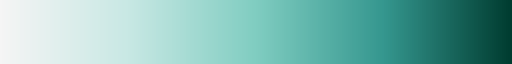

In [38]:
from matplotlib.colors import LinearSegmentedColormap

palette = [
    #"#533211",
    #"#8c5322",
    #"#dfc17c",
    #"#f5e7c3",
    "#f5f5f5",
    "#c8e8e4",
    "#80cdc1",
    "#35978f",
    #"#03675e",
    "#003c30"
]

cmap = LinearSegmentedColormap.from_list("white_teal", palette)
cmap

In [39]:
adata_a = sc.read('../adatas/iAstrocytes_SCREEN1_filtered.h5ad')
adata_a

AnnData object with n_obs × n_vars = 195306 × 36601
    obs: 'target_gene', 'guide_vector', 'sequencing_batch'

In [5]:
adata_n = sc.read('../preprocessing/adatas/iNeurons_SCREEN1_filtered_INT3INT30removed.h5ad')
adata_n

AnnData object with n_obs × n_vars = 204719 × 36601
    obs: 'Sample', 'Replicate', 'num_features', 'feature_call', 'num_umis', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'guide_calls', 'target_vector', 'target_gene', 'perturbation'
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'target_gene_id', 'target_gene_name', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Replicate_colors'

In [6]:
import pickle
with open("../DEGs/pyDESeq2/iA_DEGs_sig.pkl", "rb") as f:
    iA_DEGs_sig = pickle.load(f)

with open("../DEGs/pyDESeq2/DESeq2_iNeurons_results_v3_sig.pkl", "rb") as f:
    iN_DEGs_sig = pickle.load(f)


In [7]:
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_v3_sig_nDEGs.csv"), index_col=0)

iA_top_genes = iA_nDEGs_df[iA_nDEGs_df['nDEGs']>=5].index
iN_top_genes = iN_nDEGs_df[iN_nDEGs_df['nDEGs']>=5].index
common_genes = set(iA_top_genes) & set (iN_top_genes)
common_genes

{'CCT3',
 'CHMP7',
 'DCAF7',
 'FDFT1',
 'HDAC2',
 'LSM4',
 'MRPL39',
 'RPA3',
 'RPL10',
 'RPL30',
 'SOD1',
 'SOD2',
 'SYVN1',
 'UBA1',
 'WDR12'}

### Jaccard index heatmap

15
(15, 15)


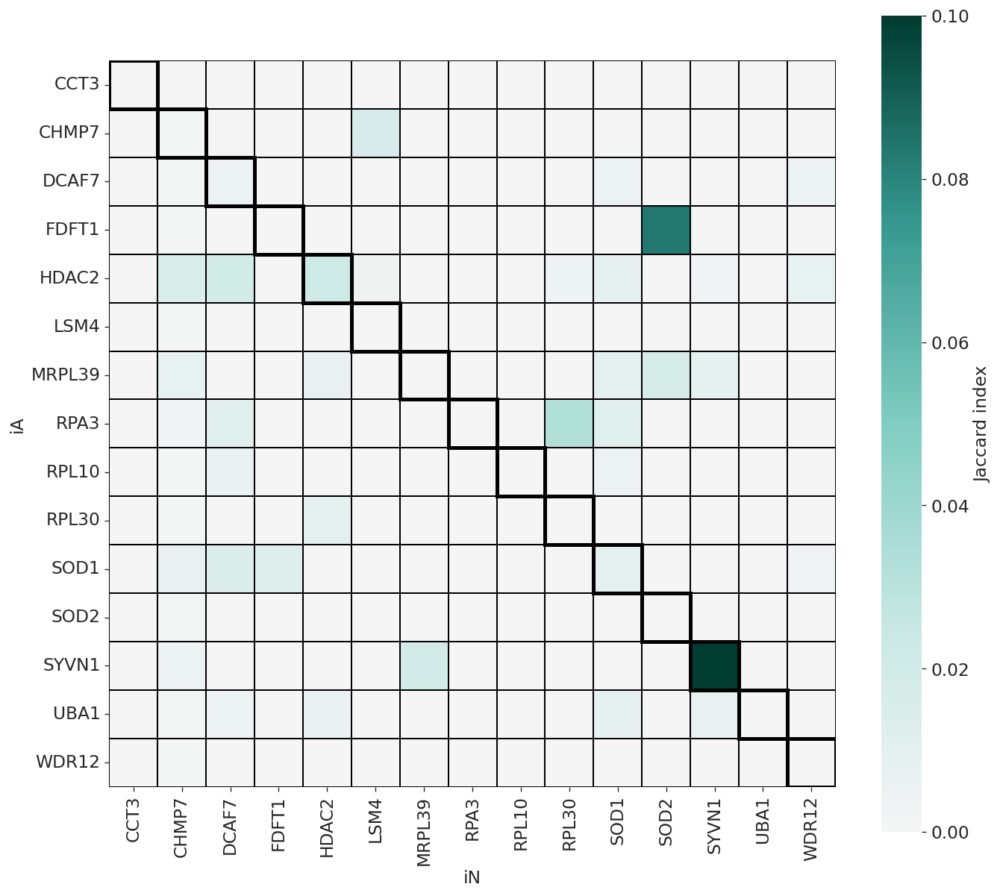

In [8]:
# Get DEG sets
iA_degs = iA_DEGs_sig.copy()
iA_degs = {k: set(v['variable']) for k, v in iA_degs.items()}

iN_degs = iN_DEGs_sig.copy()
iN_degs = {k: set(v['variable']) for k, v in iN_degs.items()}


# Perturbations with >4 DEGs in EITHER iA or iN
perts = sorted(
    set(k for k, v in iA_degs.items() if len(v) > 4 if k in common_genes) |
    set(k for k, v in iN_degs.items() if len(v) > 4 if k in common_genes)
)

print(len(perts))

# Compute cross-cell-type Jaccard similarity matrix
# rows = iA
# columns = iN

matrix = np.zeros((len(perts), len(perts)))

for i, pA in enumerate(perts):
    for j, pN in enumerate(perts):

        degs_A = iA_degs.get(pA, set())
        degs_N = iN_degs.get(pN, set())

        inter = len(degs_A & degs_N)
        union = len(degs_A | degs_N)

        matrix[i, j] = inter / union if union > 0 else 0


df = pd.DataFrame(
    matrix,
    index=perts,     # iA
    columns=perts    # iN
)

print(df.shape)

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

with sns.axes_style('ticks'):

    fig, ax = plt.subplots(figsize=(13, 12))

    sns.heatmap(
        df,
        cmap=cmap,
        vmin=0,
        vmax=0.1,
        linewidths=1,
        linecolor='black',
        square=True,
        cbar_kws={'label': 'Jaccard index'},
        ax=ax
    )

    ax.set_ylabel('iA')
    ax.set_xlabel('iN')

    # Highlight diagonal: same perturbation iA vs iN
    for i in range(len(df)):
        ax.add_patch(
            Rectangle(
                (i, i),
                1,
                1,
                fill=False,
                edgecolor='black',
                linewidth=3
            )
        )

    plt.savefig(
        'figures/jaccard_DEGs_iA_vs_iN.pdf',
        dpi=300,
        bbox_inches='tight'
    )

(30, 30)


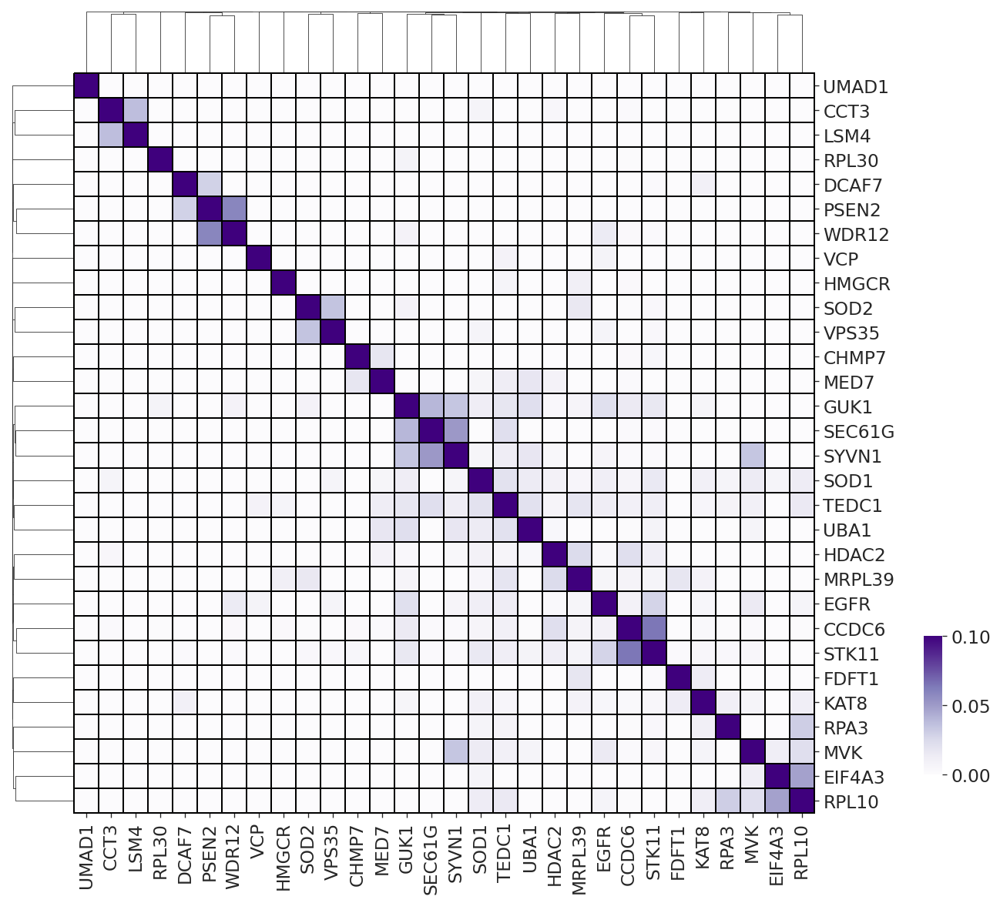

In [11]:
# Perturbation names
degs = iA_DEGs_sig.copy()

degs = {k: list(v['variable']) for k, v in degs.items()}
degs = {k: set(v) for k, v in degs.items() if len(v) > 4}

perts = list(degs.keys())

# Compute Jaccard similarity matrix
matrix = np.zeros((len(perts), len(perts)))

for i, p1 in enumerate(perts):
    for j, p2 in enumerate(perts):
        inter = len(degs[p1] & degs[p2])
        union = len(degs[p1] | degs[p2])
        matrix[i, j] = inter / union if union > 0 else 0

# Make DataFrame
df = pd.DataFrame(matrix, index=perts, columns=perts)
print(df.shape)

# Plot heatmap
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage
dist = 1 - df
# Convert to condensed form
condensed = squareform(dist.values)
# Perform clustering
link = linkage(condensed, method='average')  # or 'complete'

import seaborn as sns
with sns.axes_style('ticks'):
    sns.clustermap(df, cmap='Purples', vmax=0.1,row_linkage=link, col_linkage=link,dendrogram_ratio=(0.08, 0.08),
                   linewidths=1, linecolor='black', clip_on=False,figsize=(10,10),
                   cbar_pos=(1.01, 0.15, 0.02, 0.15)
                  )
    #plt.title("Perturbation similarity (Jaccard index)")
    plt.savefig('figures/jaccard_DEGs_iA_up2.pdf', dpi=300)

In [12]:
df

,CCDC6,CCT3,CHMP7,DCAF7,EGFR,EIF4A3,FDFT1,GUK1,HDAC2,HMGCR,KAT8,LSM4,MED7,MRPL39,MVK,PSEN2,RPA3,RPL10,RPL30,SEC61G,SOD1,SOD2,STK11,SYVN1,TEDC1,UBA1,UMAD1,VCP,VPS35,WDR12
CCDC6,1.000000,0.001801,0.002522,0.000716,0.008711,0.000361,0.000361,0.014457,0.021657,0.002502,0.002827,0.000360,0.001784,0.007148,0.002113,0.000000,0.001078,0.001080,0.001436,0.002158,0.005888,0.001441,0.064229,0.002141,0.009794,0.001408,0.0,0.000000,0.000719,0.002526
CCT3,0.001801,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.004545,0.000000,0.000000,0.037037,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.006579,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
CHMP7,0.002522,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.017544,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.005042,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
DCAF7,0.000716,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.009901,0.000000,0.000000,0.000000,0.000000,0.028571,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001639,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
EGFR,0.008711,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.021277,0.002994,0.000000,0.005000,0.000000,0.000000,0.005556,0.014563,0.000000,0.000000,0.006993,0.000000,0.000000,0.011364,0.000000,0.027496,0.005882,0.012146,0.000000,0.0,0.007463,0.006897,0.014388
EIF4A3,0.000361,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.011628,0.000000,0.000000,0.047619,0.000000,0.000000,0.006944,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
FDFT1,0.000361,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.012987,0.000000,0.000000,0.017544,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001706,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
GUK1,0.014457,0.000000,0.000000,0.000000,0.021277,0.000000,0.000000,1.000000,0.003165,0.000000,0.005495,0.000000,0.000000,0.006173,0.000000,0.000000,0.000000,0.000000,0.007519,0.039683,0.012195,0.008130,0.016153,0.033784,0.017544,0.021505,0.0,0.000000,0.000000,0.008197
HDAC2,0.021657,0.004545,0.000000,0.000000,0.002994,0.000000,0.000000,0.003165,1.000000,0.000000,0.000000,0.000000,0.008163,0.023810,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.008798,0.000000,0.011568,0.004049,0.006154,0.003521,0.0,0.000000,0.000000,0.000000
HMGCR,0.002502,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.011111,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.006289,0.000000,0.0,0.000000,0.000000,0.000000


(24, 24)


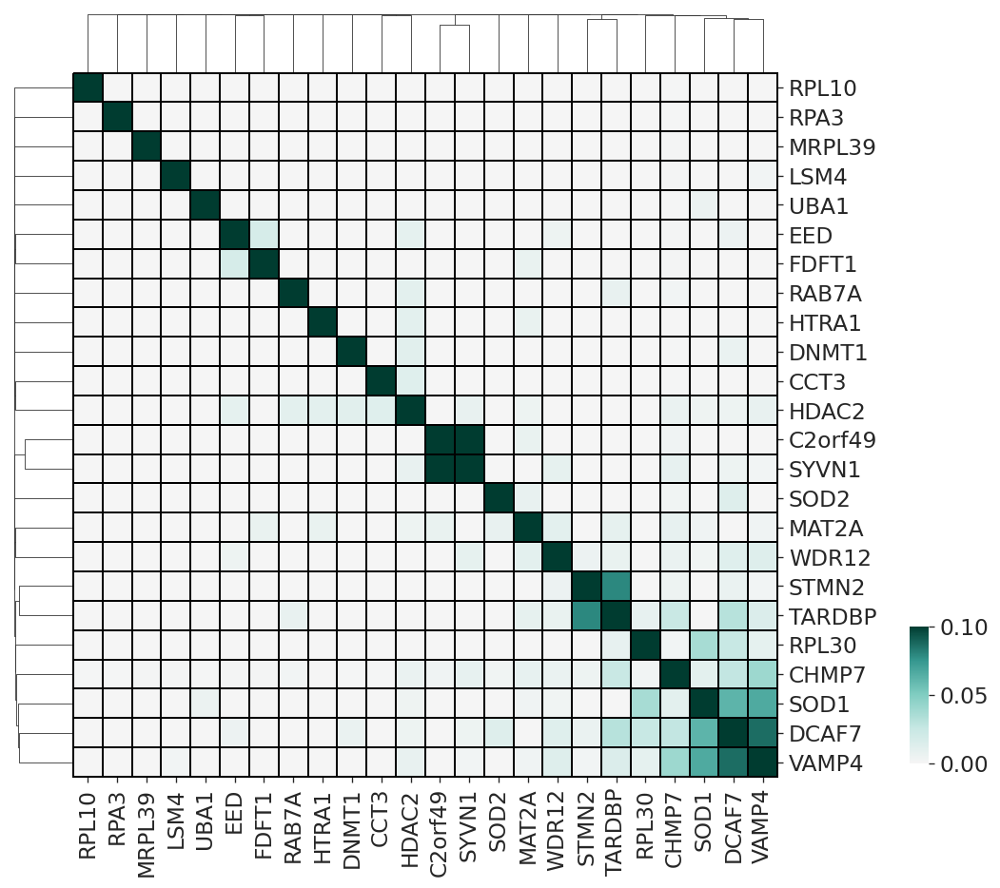

In [13]:
# Perturbation names
degs = iN_DEGs_sig.copy()

degs = {k: list(v['variable']) for k, v in degs.items()}
degs = {k: set(v) for k, v in degs.items() if len(v) > 4}

perts = list(degs.keys())

# Compute Jaccard similarity matrix
matrix = np.zeros((len(perts), len(perts)))

for i, p1 in enumerate(perts):
    for j, p2 in enumerate(perts):
        inter = len(degs[p1] & degs[p2])
        union = len(degs[p1] | degs[p2])
        matrix[i, j] = inter / union if union > 0 else 0

# Make DataFrame
df = pd.DataFrame(matrix, index=perts, columns=perts)
print(df.shape)

# Plot heatmap
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage
dist = 1 - df
# Convert to condensed form
condensed = squareform(dist.values)
# Perform clustering
link = linkage(condensed, method='average')  # or 'complete'

import seaborn as sns
with sns.axes_style('ticks'):
    sns.clustermap(df, cmap=cmap, vmax=0.1,row_linkage=link, col_linkage=link,dendrogram_ratio=(0.08, 0.08),
                   linewidths=1, linecolor='black', clip_on=False,figsize=(8,8),
                   cbar_pos=(1.01, 0.15, 0.02, 0.15)
                  )
    plt.savefig('figures/jaccard_DEGs_iN_up.pdf', dpi=300)

In [14]:
df

,C2orf49,CCT3,CHMP7,DCAF7,DNMT1,EED,FDFT1,HDAC2,HTRA1,LSM4,MAT2A,MRPL39,RAB7A,RPA3,RPL10,RPL30,SOD1,SOD2,STMN2,SYVN1,TARDBP,UBA1,VAMP4,WDR12
C2orf49,1.000000,0.000000,0.003668,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.006897,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.173913,0.000000,0.000000,0.000000,0.000000
CCT3,0.000000,1.000000,0.000739,0.000000,0.000000,0.000000,0.000000,0.012195,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
CHMP7,0.003668,0.000739,1.000000,0.026676,0.000736,0.001446,0.001460,0.006347,0.000000,0.001438,0.008197,0.001473,0.002190,0.000739,0.000732,0.002209,0.010054,0.002959,0.004438,0.007857,0.024510,0.000734,0.040140,0.005933
DCAF7,0.000000,0.000000,0.026676,1.000000,0.006173,0.005348,0.000000,0.004367,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.025000,0.061644,0.012739,0.006250,0.004695,0.031008,0.000000,0.086397,0.012308
DNMT1,0.000000,0.000000,0.000736,0.006173,1.000000,0.000000,0.000000,0.011364,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
EED,0.000000,0.000000,0.001446,0.005348,0.000000,1.000000,0.017241,0.008850,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.004717
FDFT1,0.000000,0.000000,0.001460,0.000000,0.000000,0.017241,1.000000,0.000000,0.000000,0.000000,0.006711,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
HDAC2,0.000000,0.012195,0.006347,0.004367,0.011364,0.008850,0.000000,1.000000,0.009901,0.000000,0.004902,0.000000,0.009901,0.000000,0.000000,0.000000,0.004255,0.000000,0.000000,0.007194,0.000000,0.000000,0.007797,0.000000
HTRA1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.009901,1.000000,0.000000,0.006667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
LSM4,0.000000,0.000000,0.001438,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.002075,0.000000


In [31]:
iN_DEGs_sig['STMN2']['variable'].to_list()

['STMN2',
 'TUBA1A',
 'TUBB',
 'TUBA1B',
 'TUBB3',
 'TUBB2B',
 'TUBB2A',
 'TUBB4A',
 'TUBB4B']

In [34]:
from scipy.stats import hypergeom

# DEG sets
stmn2 = set(iN_DEGs_sig['STMN2']['variable'].dropna())
tardbp = set(iN_DEGs_sig['TARDBP']['variable'].dropna())

# Genes tested in the DE analysis
background = set(adata_n.var_names)

# Restrict to background
stmn2 &= background
tardbp &= background

# Hypergeometric parameters
N = len(background)          # total genes tested
K = len(stmn2)               # STMN2 DEGs
n = len(tardbp)              # TARDBP DEGs
k = len(stmn2 & tardbp)      # shared DEGs

pval = hypergeom.sf(k - 1, N, K, n)

jaccard = k / len(stmn2 | tardbp)

print(f"Background genes: {N}")
print(f"STMN2 DEGs: {K}")
print(f"TARDBP DEGs: {n}")
print(f"Shared DEGs: {k}")
print(f"Jaccard: {jaccard:.4f}")
print(f"Hypergeometric p-value: {pval:.3e}")

Background genes: 36601
STMN2 DEGs: 9
TARDBP DEGs: 114
Shared DEGs: 9
Jaccard: 0.0789
Hypergeometric p-value: 1.997e-23


In [35]:
from scipy.stats import hypergeom

# Perturbations to compare
pert1 = "C2orf49"
pert2 = "SYVN1"

# DEG sets
degs1 = set(iN_DEGs_sig[pert1]["variable"].dropna())
degs2 = set(iN_DEGs_sig[pert2]["variable"].dropna())

# Gene universe
background = set(adata_n.var_names)

# Restrict to genes in background
degs1 &= background
degs2 &= background

# Overlap statistics
N = len(background)
K = len(degs1)
n = len(degs2)
k = len(degs1 & degs2)

union = len(degs1 | degs2)

jaccard = k / union if union else 0
overlap_pert1 = k / len(degs1) if degs1 else 0
overlap_pert2 = k / len(degs2) if degs2 else 0

# Hypergeometric test
pval = hypergeom.sf(k - 1, N, K, n)

# Results
print(f"Comparison: {pert1} vs {pert2}")
print(f"Background genes: {N}")
print(f"{pert1} DEGs: {len(degs1)}")
print(f"{pert2} DEGs: {len(degs2)}")
print(f"Shared DEGs: {k}")
print(f"Jaccard: {jaccard:.4f}")
print(f"% {pert1} DEGs shared: {overlap_pert1:.1%}")
print(f"% {pert2} DEGs shared: {overlap_pert2:.1%}")
print(f"Hypergeometric p-value: {pval:.3e}")

print("\nShared genes:")
print(sorted(degs1 & degs2))

Comparison: C2orf49 vs SYVN1
Background genes: 36601
C2orf49 DEGs: 19
SYVN1 DEGs: 62
Shared DEGs: 12
Jaccard: 0.1739
% C2orf49 DEGs shared: 63.2%
% SYVN1 DEGs shared: 19.4%
Hypergeometric p-value: 8.957e-30

Shared genes:
['ATF5', 'CHAC1', 'DDIT3', 'DDIT4', 'DMGDH', 'HERPUD1', 'MTHFD2', 'PHGDH', 'SLC1A5', 'SLC7A11', 'SLC7A3', 'WARS']


In [40]:
from scipy.stats import hypergeom

# Perturbations to compare
pert1 = "DCAF7"
pert2 = "VAMP4"

# DEG sets
degs1 = set(iN_DEGs_sig[pert1]["variable"].dropna())
degs2 = set(iN_DEGs_sig[pert2]["variable"].dropna())

# Gene universe
background = set(adata_n.var_names)

# Restrict to genes in background
degs1 &= background
degs2 &= background

# Overlap statistics
N = len(background)
K = len(degs1)
n = len(degs2)
k = len(degs1 & degs2)

union = len(degs1 | degs2)

jaccard = k / union if union else 0
overlap_pert1 = k / len(degs1) if degs1 else 0
overlap_pert2 = k / len(degs2) if degs2 else 0

# Hypergeometric test
pval = hypergeom.sf(k - 1, N, K, n)

# Results
print(f"Comparison: {pert1} vs {pert2}")
print(f"Background genes: {N}")
print(f"{pert1} DEGs: {len(degs1)}")
print(f"{pert2} DEGs: {len(degs2)}")
print(f"Shared DEGs: {k}")
print(f"Jaccard: {jaccard:.4f}")
print(f"% {pert1} DEGs shared: {overlap_pert1:.1%}")
print(f"% {pert2} DEGs shared: {overlap_pert2:.1%}")
print(f"Hypergeometric p-value: {pval:.3e}")

print("\nShared genes:")
print(sorted(degs1 & degs2))

Comparison: DCAF7 vs VAMP4
Background genes: 36601
DCAF7 DEGs: 152
VAMP4 DEGs: 439
Shared DEGs: 47
Jaccard: 0.0864
% DCAF7 DEGs shared: 30.9%
% VAMP4 DEGs shared: 10.7%
Hypergeometric p-value: 6.373e-53

Shared genes:
['AC092691.1', 'ADCY8', 'ATP6V0C', 'C9orf16', 'CASC15', 'CCNI', 'CCSER1', 'CDKAL1', 'CTXN1', 'DACH1', 'DOCK4', 'FRAS1', 'FTL', 'GPX4', 'GRIK2', 'H3F3A', 'KCNB2', 'KCND2', 'KIAA1549L', 'LRRTM4', 'MAGI2', 'MAML3', 'MIF', 'MYL6', 'NCAM1', 'NELL1', 'NME2', 'NRG1', 'PBX3', 'PCDH9', 'PPDPF', 'PPIA', 'PTPRO', 'RMST', 'ROBO1', 'RTN1', 'SELENOW', 'SEMA6D', 'SETBP1', 'SLC44A5', 'SLC8A1', 'SORBS2', 'SYN3', 'THSD7A', 'THSD7B', 'TMTC1', 'UCHL1']


In [41]:
from scipy.stats import hypergeom

# Perturbations to compare
pert1 = "DCAF7"
pert2 = "SOD1"

# DEG sets
degs1 = set(iN_DEGs_sig[pert1]["variable"].dropna())
degs2 = set(iN_DEGs_sig[pert2]["variable"].dropna())

# Gene universe
background = set(adata_n.var_names)

# Restrict to genes in background
degs1 &= background
degs2 &= background

# Overlap statistics
N = len(background)
K = len(degs1)
n = len(degs2)
k = len(degs1 & degs2)

union = len(degs1 | degs2)

jaccard = k / union if union else 0
overlap_pert1 = k / len(degs1) if degs1 else 0
overlap_pert2 = k / len(degs2) if degs2 else 0

# Hypergeometric test
pval = hypergeom.sf(k - 1, N, K, n)

# Results
print(f"Comparison: {pert1} vs {pert2}")
print(f"Background genes: {N}")
print(f"{pert1} DEGs: {len(degs1)}")
print(f"{pert2} DEGs: {len(degs2)}")
print(f"Shared DEGs: {k}")
print(f"Jaccard: {jaccard:.4f}")
print(f"% {pert1} DEGs shared: {overlap_pert1:.1%}")
print(f"% {pert2} DEGs shared: {overlap_pert2:.1%}")
print(f"Hypergeometric p-value: {pval:.3e}")

print("\nShared genes:")
print(sorted(degs1 & degs2))

Comparison: DCAF7 vs SOD1
Background genes: 36601
DCAF7 DEGs: 152
SOD1 DEGs: 158
Shared DEGs: 18
Jaccard: 0.0616
% DCAF7 DEGs shared: 11.8%
% SOD1 DEGs shared: 11.4%
Hypergeometric p-value: 6.281e-21

Shared genes:
['CADM2', 'CDH13', 'CSMD3', 'GABRG3', 'LRRTM4', 'MAGI2', 'MALAT1', 'MAML3', 'MAP2', 'NELL1', 'NXPH1', 'PCDH9', 'RASGEF1B', 'ROBO1', 'SEMA6D', 'SLC8A1', 'SLIT3', 'SORBS2']


In [42]:
from scipy.stats import hypergeom

# Perturbations to compare
pert1 = "VAMP4"
pert2 = "SOD1"

# DEG sets
degs1 = set(iN_DEGs_sig[pert1]["variable"].dropna())
degs2 = set(iN_DEGs_sig[pert2]["variable"].dropna())

# Gene universe
background = set(adata_n.var_names)

# Restrict to genes in background
degs1 &= background
degs2 &= background

# Overlap statistics
N = len(background)
K = len(degs1)
n = len(degs2)
k = len(degs1 & degs2)

union = len(degs1 | degs2)

jaccard = k / union if union else 0
overlap_pert1 = k / len(degs1) if degs1 else 0
overlap_pert2 = k / len(degs2) if degs2 else 0

# Hypergeometric test
pval = hypergeom.sf(k - 1, N, K, n)

# Results
print(f"Comparison: {pert1} vs {pert2}")
print(f"Background genes: {N}")
print(f"{pert1} DEGs: {len(degs1)}")
print(f"{pert2} DEGs: {len(degs2)}")
print(f"Shared DEGs: {k}")
print(f"Jaccard: {jaccard:.4f}")
print(f"% {pert1} DEGs shared: {overlap_pert1:.1%}")
print(f"% {pert2} DEGs shared: {overlap_pert2:.1%}")
print(f"Hypergeometric p-value: {pval:.3e}")

print("\nShared genes:")
print(sorted(degs1 & degs2))

Comparison: VAMP4 vs SOD1
Background genes: 36601
VAMP4 DEGs: 439
SOD1 DEGs: 158
Shared DEGs: 37
Jaccard: 0.0661
% VAMP4 DEGs shared: 8.4%
% SOD1 DEGs shared: 23.4%
Hypergeometric p-value: 8.067e-37

Shared genes:
['AC233296.1', 'ANKS1B', 'ASAP1', 'AUTS2', 'CADPS', 'CDH8', 'CTNNA2', 'CTTNBP2', 'DSCAM', 'FAM155A', 'FBXL7', 'FTX', 'KAZN', 'KCNH7', 'LRRTM4', 'MACROD2', 'MAGI2', 'MAML3', 'MYO16', 'NBAS', 'NCAM2', 'NELL1', 'NLGN1', 'NPAS3', 'NYAP2', 'PCDH9', 'PLCL1', 'PTPRT', 'ROBO1', 'SEMA6D', 'SLC8A1', 'SMYD3', 'SNHG14', 'SORBS2', 'TENM2', 'TTC28', 'WDFY3']


In [43]:
from scipy.stats import hypergeom

# Perturbations to compare
pert1 = "CCDC6"
pert2 = "STK11"

# DEG sets
degs1 = set(iA_DEGs_sig[pert1]["variable"].dropna())
degs2 = set(iA_DEGs_sig[pert2]["variable"].dropna())

# Gene universe
background = set(adata_n.var_names)

# Restrict to genes in background
degs1 &= background
degs2 &= background

# Overlap statistics
N = len(background)
K = len(degs1)
n = len(degs2)
k = len(degs1 & degs2)

union = len(degs1 | degs2)

jaccard = k / union if union else 0
overlap_pert1 = k / len(degs1) if degs1 else 0
overlap_pert2 = k / len(degs2) if degs2 else 0

# Hypergeometric test
pval = hypergeom.sf(k - 1, N, K, n)

# Results
print(f"Comparison: {pert1} vs {pert2}")
print(f"Background genes: {N}")
print(f"{pert1} DEGs: {len(degs1)}")
print(f"{pert2} DEGs: {len(degs2)}")
print(f"Shared DEGs: {k}")
print(f"Jaccard: {jaccard:.4f}")
print(f"% {pert1} DEGs shared: {overlap_pert1:.1%}")
print(f"% {pert2} DEGs shared: {overlap_pert2:.1%}")
print(f"Hypergeometric p-value: {pval:.3e}")

print("\nShared genes:")
print(sorted(degs1 & degs2))

Comparison: CCDC6 vs STK11
Background genes: 36601
CCDC6 DEGs: 2766
STK11 DEGs: 581
Shared DEGs: 202
Jaccard: 0.0642
% CCDC6 DEGs shared: 7.3%
% STK11 DEGs shared: 34.8%
Hypergeometric p-value: 8.366e-81

Shared genes:
['A1BG', 'A1BG-AS1', 'ABHD12', 'AC004943.2', 'AC009975.1', 'AC092574.2', 'AC098595.1', 'ADAMTS2', 'ADAMTS8', 'ADCYAP1', 'AHNAK2', 'AK1', 'ALDH7A1', 'ANO6', 'ANP32A', 'AP001347.1', 'ARHGAP31', 'ATP11B', 'AXL', 'BMP1', 'BRK1', 'BST1', 'BZW1', 'C19orf53', 'C21orf91', 'C3', 'C9orf16', 'CA14', 'CA2', 'CA8', 'CASC4', 'CCDC138', 'CCDC88C', 'CD63', 'CDH4', 'CHEK1', 'CHN1', 'CHPF', 'CHSY1', 'CKAP5', 'CLEC16A', 'CLEC3B', 'CMSS1', 'CNKSR2', 'COL1A1', 'COL4A6', 'CPQ', 'CREB3', 'CSE1L', 'CTPS1', 'CTSA', 'DBF4B', 'DCAF13', 'DDX39A', 'DHFR', 'DHX9', 'DNA2', 'DNAJC9', 'DNMT1', 'DYNC2H1', 'DYNLT1', 'E2F5', 'EBLN3P', 'EBPL', 'EFR3A', 'EHD2', 'EIF4A3', 'EMID1', 'FGFR1OP', 'FGFR2', 'FIS1', 'FKBP9', 'FN3KRP', 'FNDC1', 'FOXP2', 'FRMD6', 'FSTL3', 'FUBP1', 'G3BP1', 'GAS1', 'GET3', 'GGCT', 'GINS

### GO heatmap

In [15]:
import requests
def get_enrichr_library(library_name):
    url = "https://maayanlab.cloud/Enrichr/geneSetLibrary"
    r = requests.get(
        url,
        params={"mode": "text", "libraryName": library_name},
        timeout=60,
    )
    r.raise_for_status()
    genesets = {}
    for line in r.text.strip().splitlines():
        parts = line.split("\t")
        genesets[parts[0]] = [g.split(",")[0] for g in parts[2:]]
    return genesets

#tabula = get_enrichr_library("Tabula_Sapiens")
GO = get_enrichr_library("GO_Biological_Process_2025")
reactome = get_enrichr_library("Reactome_Pathways_2024")
hallmarks = get_enrichr_library("MSigDB_Hallmark_2020")
kegg = get_enrichr_library("KEGG_2021_Human")
go_mf = get_enrichr_library("GO_Molecular_Function_2025")
go_cc = get_enrichr_library("GO_Cellular_Component_2025")
wiki = get_enrichr_library("WikiPathways_2024_Human")
archs4_tissues = get_enrichr_library("ARCHS4_Tissues")
gtex_tissues = get_enrichr_library("GTEx_Tissues_V8_2023")
human_gene_atlas = get_enrichr_library("Human_Gene_Atlas")
cellmarker = get_enrichr_library("CellMarker_2024")
panglao = get_enrichr_library("PanglaoDB_Augmented_2021")
azimuth = get_enrichr_library("Azimuth_2023")
descartes = get_enrichr_library("Descartes_Cell_Types_and_Tissue_2021")
compartments = get_enrichr_library("COMPARTMENTS_Curated_2025")
tissues_curated = get_enrichr_library("TISSUES_Curated_2025")

In [16]:
import gseapy as gp

def enrichment_heatmap(gene_dict, gene_sets=None, organism='human', top_n=5, fdr_cutoff=0.05):
    """
    Perform enrichment analysis and create a heatmap of top GO terms.

    Parameters:
        gene_dict (dict): Dictionary containing list of genes to perform GEA on
        gene_sets (list): List of gene sets for enrichment analysis (default GO + MSigDB).
        organism (str): Organism for enrichment ('human', 'mouse', etc.).
        top_n (int): Number of GO terms to keep.
        fdr_cutoff (float): FDR threshold for significance.

    Returns:
        GO_res (DataFrame): Filtered -log10(p-value) enrichment matrix.
        enr_dict (dict): Dictionary of raw enrichment results per perturbation.
    """
    
    if gene_sets is None:
        gene_sets = ['GO_Biological_Process_2025','MSigDB_Hallmark_2020','GO_Cellular_Component_2025','GO_Molecular_Function_2025',
                     'Reactome_2022','CellMarker_2024' #'Reactome_Pathways_2024',
                    ]

    # Run enrichment for each GP
    enr_dict = {}
    for key in gene_dict:
        enr = gp.enrichr(
            gene_list=gene_dict[key]['variable'].to_list(),
            gene_sets=gene_sets,
            organism=organism,
            outdir=None
        )
        if isinstance(enr.results, pd.DataFrame) and not enr.results.empty:
            enr_dict[key] = enr.results.sort_values("Adjusted P-value")
        else:
            print(f"No enrichment results for {key}")
            enr_dict[key] = pd.DataFrame(columns=["Term", "Adjusted P-value"])

    # Transform results to -log10(p-value)
    pvalues = {}
    for key, df in enr_dict.items():
        df_top = df[["Term","Adjusted P-value"]].head(top_n).copy()
        df_top = df_top.rename(columns={'Adjusted P-value': key}).set_index("Term")
        df_top[key] = -np.log10(df_top[key])
        pvalues[key] = df_top

    minuslogp = pd.concat(pvalues.values(), axis=0, join="outer")
    minuslogp = minuslogp.groupby(level=0).sum()

    # keep significant GO terms
    minuslogp_bool = (minuslogp <= -np.log10(fdr_cutoff)).all(axis=1)
    GO_res = minuslogp[~minuslogp_bool]

    print(f"GO terms shape (significant): {GO_res.shape}")
    
    return GO_res, enr_dict

In [17]:
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_v3_sig_nDEGs.csv"), index_col=0)

In [18]:
iA_top_genes = iA_nDEGs_df[iA_nDEGs_df['nDEGs']>=5].index
iN_top_genes = iN_nDEGs_df[iN_nDEGs_df['nDEGs']>=5].index
common_genes = set(iA_top_genes) & set (iN_top_genes)
common_genes

{'CCT3',
 'CHMP7',
 'DCAF7',
 'FDFT1',
 'HDAC2',
 'LSM4',
 'MRPL39',
 'RPA3',
 'RPL10',
 'RPL30',
 'SOD1',
 'SOD2',
 'SYVN1',
 'UBA1',
 'WDR12'}

In [19]:
GO_res_a, enr_dict = enrichment_heatmap(
    gene_dict={k:v for k,v in iA_DEGs_sig.items() if k in iA_top_genes},
    gene_sets=[GO, reactome, hallmarks, kegg, ],#go_mf, go_cc, wiki,],
    top_n=6,
    fdr_cutoff=0.01,
)

GO terms shape (significant): (59, 30)


In [20]:
GO_res_a.to_csv('topDEGs_GEA_iAstrocytes.csv')

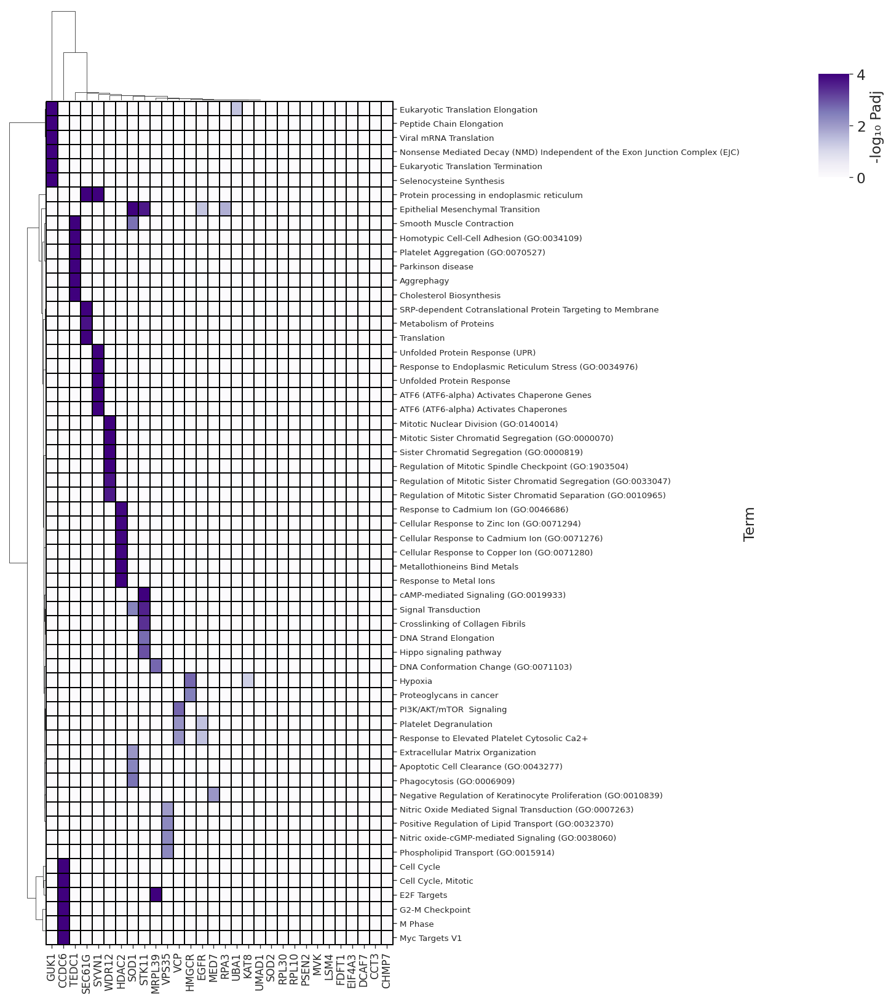

In [21]:
g = sns.clustermap(
    GO_res_a,
    vmax=4, cmap='Purples', linewidths=1, linecolor='black', clip_on=False,
    dendrogram_ratio = 0.1,
    figsize=(14,14),
    cbar_pos=(0.8, 0.82, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    yticklabels=1,   # force every row label
    #xticklabels=1    # force every column label (optional)
)

# Shrink fonts after creation
g.ax_heatmap.tick_params(axis='y', labelsize=8)
g.ax_heatmap.tick_params(axis='x', labelsize=10, )
plt.savefig("figures/DESeq2_iAstrocytes_topPerturbatons_GO.pdf")

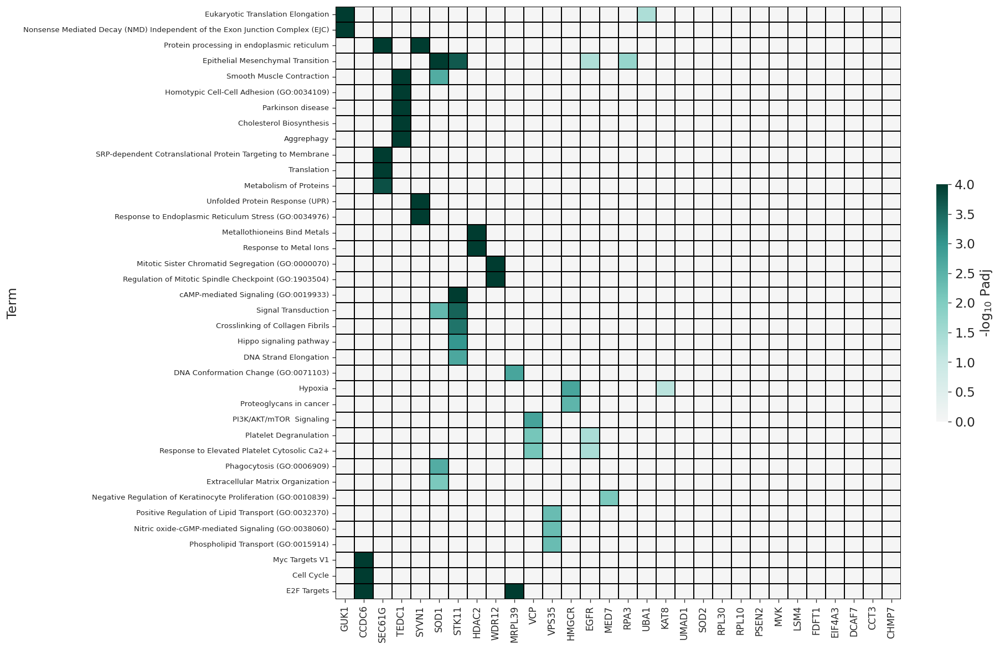

In [22]:
terms_by_perturbation = {
    "CCDC6": [
        "Cell Cycle",
        "E2F Targets",
        "Myc Targets V1",
    ],
    "EGFR": [
        "Platelet Degranulation",
        "Epithelial Mesenchymal Transition",
    ],
    "GUK1": [
        "Eukaryotic Translation Elongation",
        "Nonsense Mediated Decay (NMD) Independent of the Exon Junction Complex (EJC)",
    ],
    "HDAC2": [
        "Metallothioneins Bind Metals",
        "Response to Metal Ions",
    ],
    "HMGCR": [
        "Hypoxia",
        "Proteoglycans in cancer",
    ],
    "KAT8": [
        "Hypoxia",
    ],
    "MED7": [
        "Negative Regulation of Keratinocyte Proliferation (GO:0010839)",
    ],
    "MRPL39": [
        "E2F Targets",
        "DNA Conformation Change (GO:0071103)",
    ],
    "RPA3": [
        "Epithelial Mesenchymal Transition",
    ],
    "SEC61G": [
        "Protein processing in endoplasmic reticulum",
        "SRP-dependent Cotranslational Protein Targeting to Membrane",
        "Translation",'Metabolism of Proteins'
    ],
    "SOD1": [
        "Epithelial Mesenchymal Transition",
        "Phagocytosis (GO:0006909)",
        "Signal Transduction",
        "Extracellular Matrix Organization",
    ],
    "STK11": [
        "cAMP-mediated Signaling (GO:0019933)",
        "Epithelial Mesenchymal Transition",
        "Hippo signaling pathway",
        "Crosslinking of Collagen Fibrils",
        "DNA Strand Elongation",
    ],
    "SYVN1": [
        "Protein processing in endoplasmic reticulum",
        "Unfolded Protein Response (UPR)",
        'Response to Endoplasmic Reticulum Stress (GO:0034976)'
    ],
    "TEDC1": [
        "Smooth Muscle Contraction",
        "Parkinson disease",
        "Cholesterol Biosynthesis",
        "Aggrephagy",
        "Homotypic Cell-Cell Adhesion (GO:0034109)",
    ],
    "UBA1": [
        "Eukaryotic Translation Elongation",
    ],
    "VCP": [
        "PI3K/AKT/mTOR  Signaling",
        "Platelet Degranulation","Response to Elevated Platelet Cytosolic Ca2+"
    ],
    "VPS35": [
        "Nitric oxide-cGMP-mediated Signaling (GO:0038060)",
        "Phospholipid Transport (GO:0015914)","Positive Regulation of Lipid Transport (GO:0032370)"
    ],
    "WDR12": [
        "Mitotic Sister Chromatid Segregation (GO:0000070)",
        "Regulation of Mitotic Spindle Checkpoint (GO:1903504)",
    ],
}

terms_to_plot = list(dict.fromkeys(
    term
    for terms in terms_by_perturbation.values()
    for term in terms
))

# First compute the clustering only
g = sns.clustermap(
    GO_res_a.loc[terms_to_plot],
    vmax=4,
    cmap=cmap,
    linewidths=1,
    linecolor="black",
    figsize=(16, 10),
    cbar_pos=None,   # don't draw colourbar yet
)

# Extract clustered order
row_order = g.dendrogram_row.reordered_ind
col_order = g.dendrogram_col.reordered_ind

plt.close(g.fig)

# Reorder dataframe
plot_df = GO_res_a.loc[terms_to_plot].iloc[row_order, col_order]

# Draw as a normal heatmap
fig, ax = plt.subplots(figsize=(16, 10))

sns.heatmap(
    plot_df,
    ax=ax,
    vmax=4,
    cmap=cmap,
    linewidths=1,
    linecolor="black",
    cbar_kws={"label": r"-log$_{10}$ Padj", "shrink": 0.4},
)

ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10, rotation=90)

plt.tight_layout()
plt.savefig("figures/DESeq2_iAstrocytes_topPerturbatons_GO2.pdf")


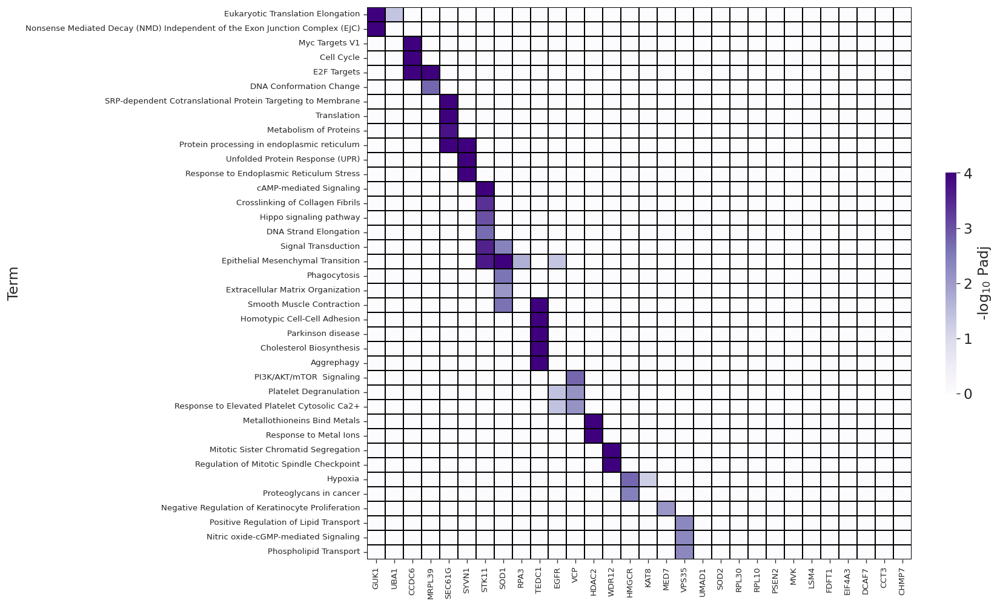

In [23]:
order_perts = ['GUK1', 'UBA1', 'CCDC6', 'MRPL39', 'SEC61G', 'SYVN1', 'STK11', 'SOD1', 'RPA3', 'TEDC1' ,'EGFR','VCP',
                'HDAC2',
               'WDR12', 'HMGCR','KAT8',  'MED7','VPS35',
                'UMAD1', 'SOD2', 'RPL30', 'RPL10', 'PSEN2', 'MVK',
               'LSM4', 'FDFT1', 'EIF4A3', 'DCAF7', 'CCT3', 'CHMP7']

order_GO= ['Eukaryotic Translation Elongation','Nonsense Mediated Decay (NMD) Independent of the Exon Junction Complex (EJC)',
           'Myc Targets V1', 'Cell Cycle','E2F Targets','DNA Conformation Change (GO:0071103)',
           'SRP-dependent Cotranslational Protein Targeting to Membrane','Translation', 'Metabolism of Proteins',
       'Protein processing in endoplasmic reticulum','Unfolded Protein Response (UPR)','Response to Endoplasmic Reticulum Stress (GO:0034976)',
       'cAMP-mediated Signaling (GO:0019933)','Crosslinking of Collagen Fibrils', 'Hippo signaling pathway',
       'DNA Strand Elongation','Signal Transduction',
        'Epithelial Mesenchymal Transition',
           'Phagocytosis (GO:0006909)', 'Extracellular Matrix Organization','Smooth Muscle Contraction',
           'Homotypic Cell-Cell Adhesion (GO:0034109)', 'Parkinson disease','Cholesterol Biosynthesis', 'Aggrephagy',
           'PI3K/AKT/mTOR  Signaling','Platelet Degranulation','Response to Elevated Platelet Cytosolic Ca2+',
       
       'Metallothioneins Bind Metals', 'Response to Metal Ions',
       'Mitotic Sister Chromatid Segregation (GO:0000070)',
       'Regulation of Mitotic Spindle Checkpoint (GO:1903504)',
       'Hypoxia', 'Proteoglycans in cancer', 
       'Negative Regulation of Keratinocyte Proliferation (GO:0010839)',
       'Positive Regulation of Lipid Transport (GO:0032370)',
       'Nitric oxide-cGMP-mediated Signaling (GO:0038060)',
       'Phospholipid Transport (GO:0015914)', ]

toplot_iA = GO_res_a.loc[order_GO,order_perts]
toplot_iA.index = (
    toplot_iA.index
    .str.replace(r" \(GO:\d+\)", "", regex=True)
)

fig, ax = plt.subplots(figsize=(12, 10))


sns.heatmap(
    toplot_iA,
    ax=ax,
    vmax=4,
    cmap='Purples',
    linewidths=1,
    linecolor="black",
    cbar_kws={"label": r"-log$_{10}$ Padj", "shrink": 0.4},
)

ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=8, rotation=90)

#plt.tight_layout()
plt.savefig("figures/DESeq2_iAstrocytes_topPerturbatons_GO_final.pdf")

In [24]:
GO_res_n, enr_dict = enrichment_heatmap(
    gene_dict={k:v for k,v in iN_DEGs_sig.items() if k in iN_top_genes},
    gene_sets=[GO, reactome, hallmarks, kegg], #go_mf, go_cc, wiki,],
    top_n=6,
    fdr_cutoff=0.01,
)

GO_res_n.to_csv('topDEGs_GEA_iNeurons.csv')

GO terms shape (significant): (68, 24)


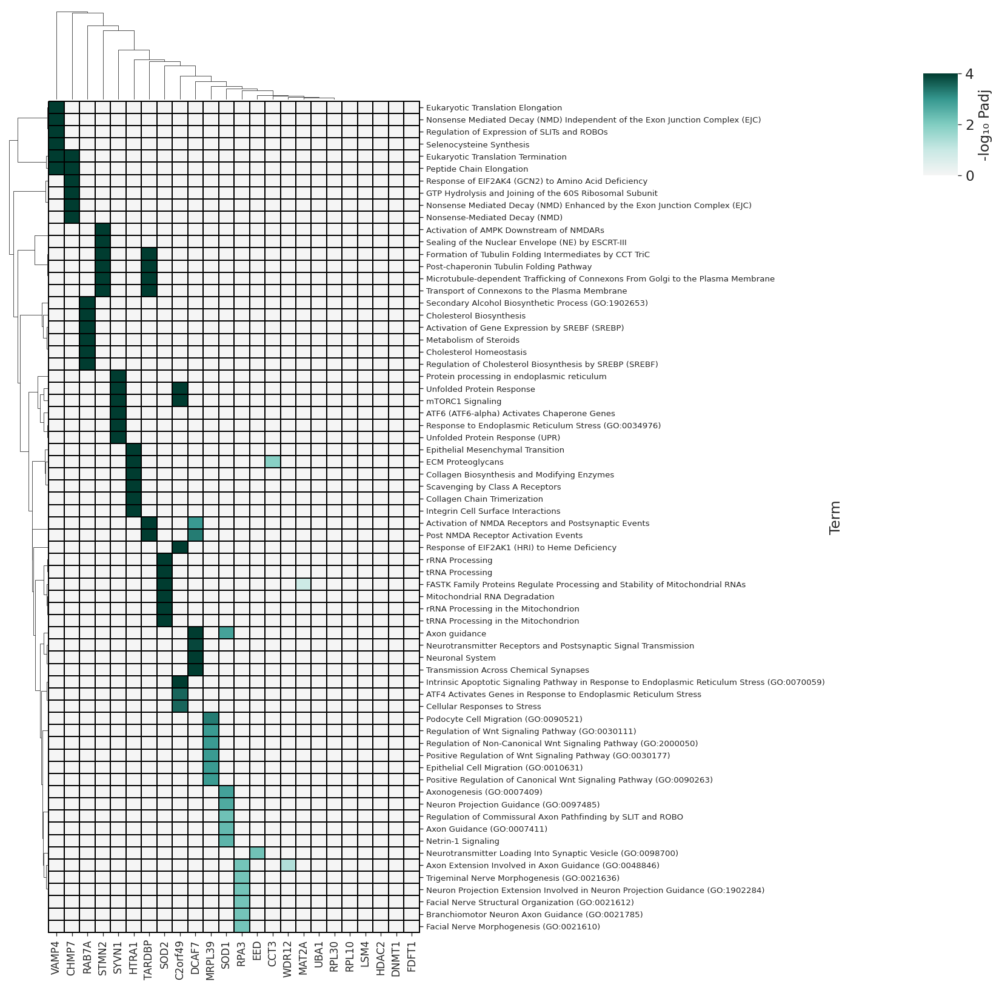

In [25]:
g = sns.clustermap(
    GO_res_n,
    vmax=4, cmap=cmap, linewidths=1, linecolor='black', clip_on=False,
    dendrogram_ratio = 0.1,
    figsize=(16,14),
    cbar_pos=(0.8, 0.82, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    yticklabels=1,   # force every row label
    #xticklabels=1    # force every column label (optional)
)

# Shrink fonts after creation
g.ax_heatmap.tick_params(axis='y', labelsize=8)
g.ax_heatmap.tick_params(axis='x', labelsize=10, )
plt.savefig("figures/DESeq2_iNeurons_topPerturbatons_GO.pdf")

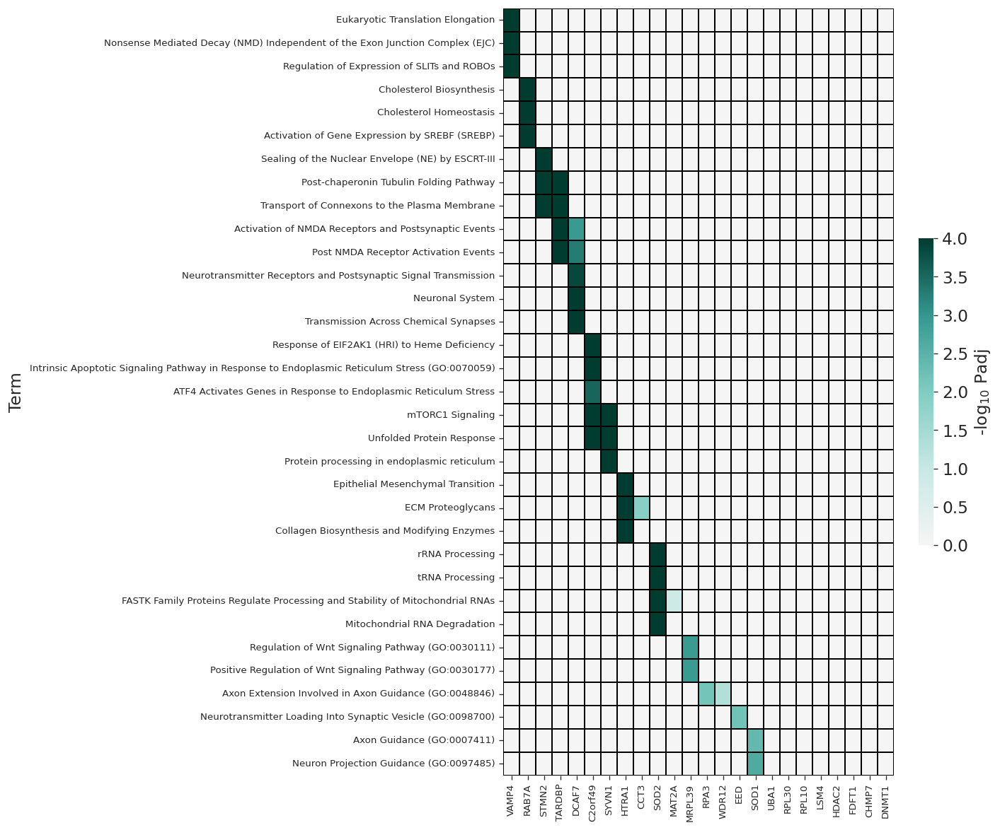

In [26]:
order_perts = ['VAMP4', 'RAB7A', 'STMN2','TARDBP','DCAF7','C2orf49','SYVN1', 'HTRA1','CCT3', 'SOD2','MAT2A',
       'MRPL39', 'RPA3', 'WDR12', 'EED', 'SOD1',
       'UBA1', 'RPL30', 'RPL10', 'LSM4', 'HDAC2', 'FDFT1', 'CHMP7',
       'DNMT1']

order_GO= ['Eukaryotic Translation Elongation',
       'Nonsense Mediated Decay (NMD) Independent of the Exon Junction Complex (EJC)',
       'Regulation of Expression of SLITs and ROBOs',
       'Cholesterol Biosynthesis', 'Cholesterol Homeostasis',
       'Activation of Gene Expression by SREBF (SREBP)',
       'Sealing of the Nuclear Envelope (NE) by ESCRT-III',
       #'Formation of Tubulin Folding Intermediates by CCT TriC',
       'Post-chaperonin Tubulin Folding Pathway',
       #'Microtubule-dependent Trafficking of Connexons From Golgi to the Plasma Membrane',
       'Transport of Connexons to the Plasma Membrane',
        'Activation of NMDA Receptors and Postsynaptic Events',
       'Post NMDA Receptor Activation Events',
           'Neurotransmitter Receptors and Postsynaptic Signal Transmission',
       'Neuronal System', 'Transmission Across Chemical Synapses',
           'Response of EIF2AK1 (HRI) to Heme Deficiency',
        'Intrinsic Apoptotic Signaling Pathway in Response to Endoplasmic Reticulum Stress (GO:0070059)',
       'ATF4 Activates Genes in Response to Endoplasmic Reticulum Stress',
       #'Cellular Responses to Stress',
           'mTORC1 Signaling',
           'Unfolded Protein Response',
       'Protein processing in endoplasmic reticulum',
       #'Unfolded Protein Response (UPR)', 
           'Epithelial Mesenchymal Transition',
       'ECM Proteoglycans', 'Collagen Biosynthesis and Modifying Enzymes',
        'rRNA Processing',
       'tRNA Processing',
       'FASTK Family Proteins Regulate Processing and Stability of Mitochondrial RNAs',
       'Mitochondrial RNA Degradation',
       'Regulation of Wnt Signaling Pathway (GO:0030111)',
       'Positive Regulation of Wnt Signaling Pathway (GO:0030177)',
       'Axon Extension Involved in Axon Guidance (GO:0048846)',
       'Neurotransmitter Loading Into Synaptic Vesicle (GO:0098700)',
       'Axon Guidance (GO:0007411)',
       'Neuron Projection Guidance (GO:0097485)']

toplot_iN = GO_res_n.loc[order_GO,order_perts]
toplot_iN.index = (
    toplot_iN.index
    .str.replace(r" \(GO:\d+\)", "", regex=True)
)


fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    GO_res_n.loc[order_GO,order_perts],
    ax=ax,
    vmax=4,
    cmap=cmap,
    linewidths=1,
    linecolor="black",
    cbar_kws={"label": r"-log$_{10}$ Padj", "shrink": 0.4},
)

ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=8, rotation=90)

plt.tight_layout()
plt.savefig("figures/DESeq2_iNeurons_topPerturbatons_GO_final.pdf")

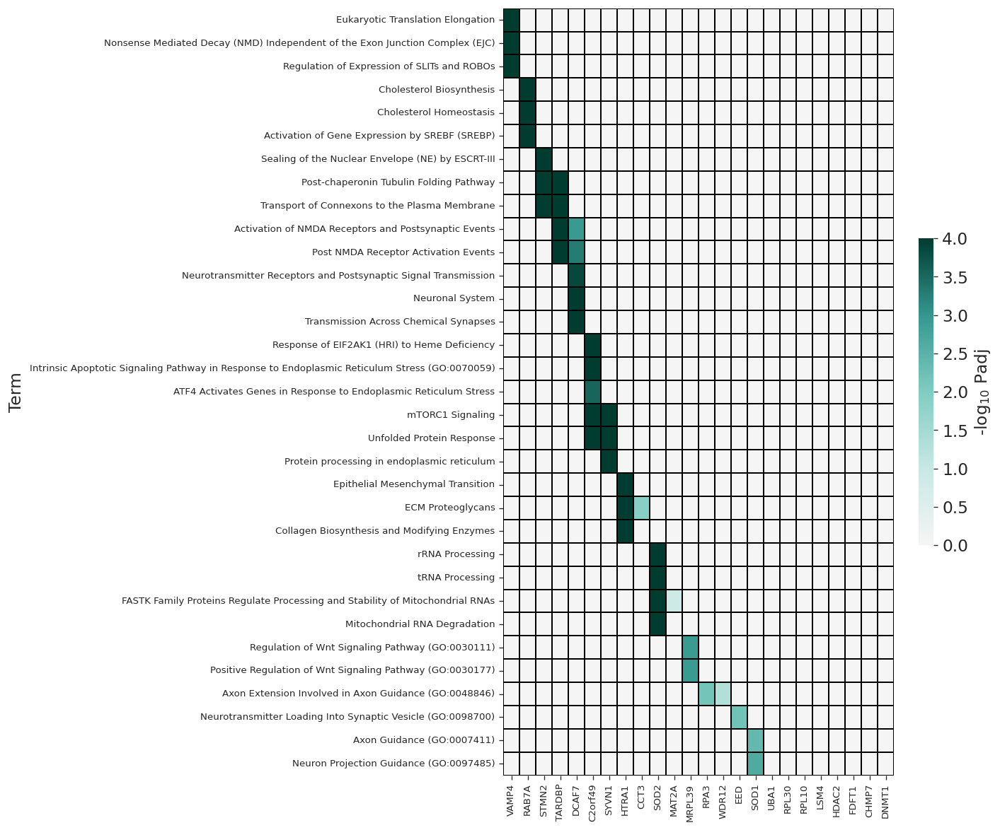

In [27]:
order_perts = ['VAMP4', 'RAB7A', 'STMN2','TARDBP','DCAF7','C2orf49','SYVN1', 'HTRA1','CCT3', 'SOD2','MAT2A',
       'MRPL39', 'RPA3', 'WDR12', 'EED', 'SOD1',
       'UBA1', 'RPL30', 'RPL10', 'LSM4', 'HDAC2', 'FDFT1', 'CHMP7',
       'DNMT1']

order_GO= ['Eukaryotic Translation Elongation',
       'Nonsense Mediated Decay (NMD) Independent of the Exon Junction Complex (EJC)',
       'Regulation of Expression of SLITs and ROBOs',
       'Cholesterol Biosynthesis', 'Cholesterol Homeostasis',
       'Activation of Gene Expression by SREBF (SREBP)',
       'Sealing of the Nuclear Envelope (NE) by ESCRT-III',
       #'Formation of Tubulin Folding Intermediates by CCT TriC',
       'Post-chaperonin Tubulin Folding Pathway',
       #'Microtubule-dependent Trafficking of Connexons From Golgi to the Plasma Membrane',
       'Transport of Connexons to the Plasma Membrane',
        'Activation of NMDA Receptors and Postsynaptic Events',
       'Post NMDA Receptor Activation Events',
           'Neurotransmitter Receptors and Postsynaptic Signal Transmission',
       'Neuronal System', 'Transmission Across Chemical Synapses',
           'Response of EIF2AK1 (HRI) to Heme Deficiency',
        'Intrinsic Apoptotic Signaling Pathway in Response to Endoplasmic Reticulum Stress (GO:0070059)',
       'ATF4 Activates Genes in Response to Endoplasmic Reticulum Stress',
       #'Cellular Responses to Stress',
           'mTORC1 Signaling',
           'Unfolded Protein Response',
       'Protein processing in endoplasmic reticulum',
       #'Unfolded Protein Response (UPR)', 
           'Epithelial Mesenchymal Transition',
       'ECM Proteoglycans', 'Collagen Biosynthesis and Modifying Enzymes',
        'rRNA Processing',
       'tRNA Processing',
       'FASTK Family Proteins Regulate Processing and Stability of Mitochondrial RNAs',
       'Mitochondrial RNA Degradation',
       'Regulation of Wnt Signaling Pathway (GO:0030111)',
       'Positive Regulation of Wnt Signaling Pathway (GO:0030177)',
       'Axon Extension Involved in Axon Guidance (GO:0048846)',
       'Neurotransmitter Loading Into Synaptic Vesicle (GO:0098700)',
       'Axon Guidance (GO:0007411)',
       'Neuron Projection Guidance (GO:0097485)']

toplot_iN = GO_res_n.loc[order_GO,order_perts]
toplot_iN.index = (
    toplot_iN.index
    .str.replace(r" \(GO:\d+\)", "", regex=True)
)


fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    GO_res_n.loc[order_GO,order_perts],
    ax=ax,
    vmax=4,
    cmap=cmap,
    linewidths=1,
    linecolor="black",
    cbar_kws={"label": r"-log$_{10}$ Padj", "shrink": 0.4},
)

ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=8, rotation=90)

plt.tight_layout()
plt.savefig("figures/DESeq2_iNeurons_topPerturbatons_GO_final.pdf")

### compare bar plot with # DEGs

In [7]:
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_v3_sig_nDEGs.csv"), index_col=0)

In [8]:
iA_top_genes = iA_nDEGs_df[iA_nDEGs_df['nDEGs']>=5].index
iN_top_genes = iN_nDEGs_df[iN_nDEGs_df['nDEGs']>=5].index
common_genes = set(iA_top_genes) & set (iN_top_genes)
common_genes

{'CCT3',
 'CHMP7',
 'DCAF7',
 'FDFT1',
 'HDAC2',
 'LSM4',
 'MRPL39',
 'RPA3',
 'RPL10',
 'RPL30',
 'SOD1',
 'SOD2',
 'SYVN1',
 'UBA1',
 'WDR12'}

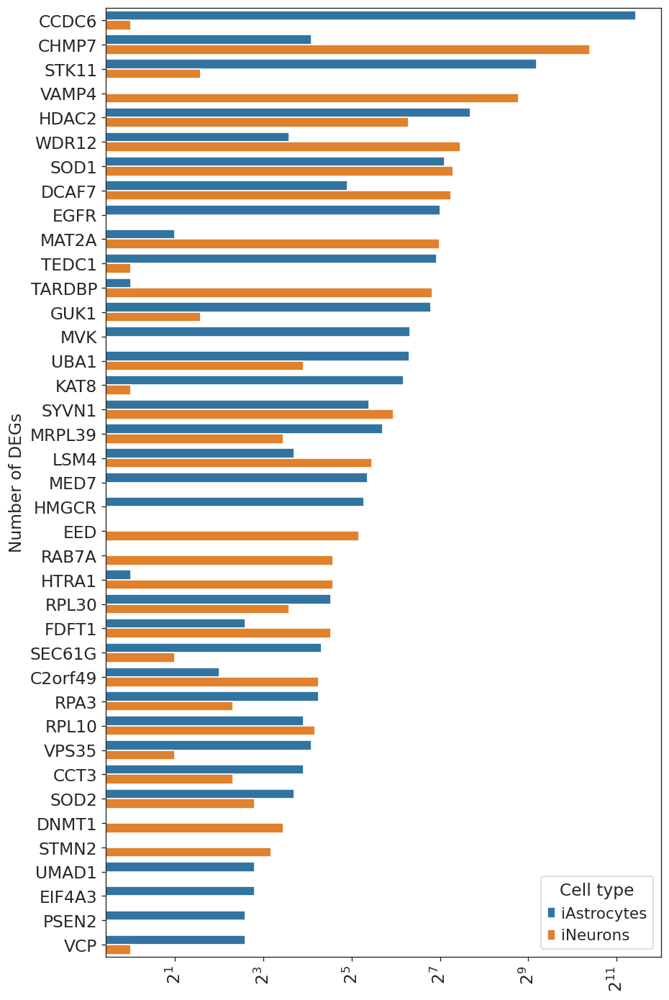

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

genes = sorted(set(iA_top_genes) | set(iN_top_genes))

plot_df = pd.DataFrame({
    "Gene": genes,
    "iAstrocytes": iA_nDEGs_df["nDEGs"].reindex(genes).fillna(0).astype(int).values,
    "iNeurons": iN_nDEGs_df["nDEGs"].reindex(genes).fillna(0).astype(int).values,
})

plot_df = plot_df.assign(
    max_nDEGs=plot_df[["iAstrocytes", "iNeurons"]].max(axis=1)
).sort_values("max_nDEGs", ascending=False).drop(columns="max_nDEGs")

plot_df = plot_df.melt(
    id_vars="Gene",
    var_name="Cell type",
    value_name="nDEGs"
)

plt.figure(figsize=(8, 12))
sns.barplot(data=plot_df, y="Gene", x="nDEGs", hue="Cell type")
plt.xticks(rotation=90)
plt.ylabel("Number of DEGs")
plt.xlabel("")
plt.tight_layout()
plt.xscale("log", base=2)

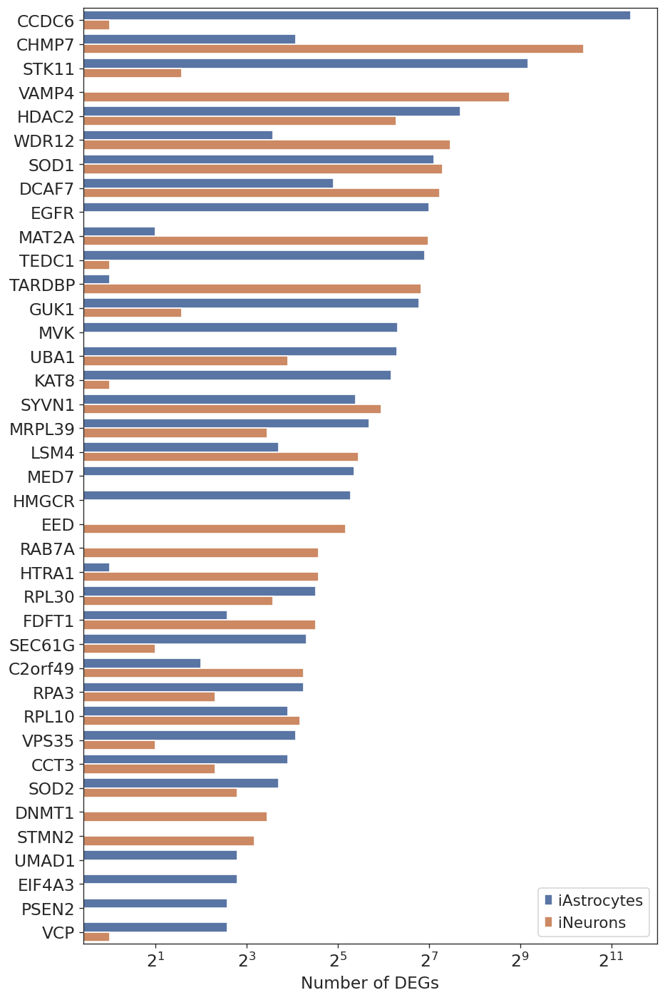

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

genes = sorted(set(iA_top_genes) | set(iN_top_genes))

plot_df = pd.DataFrame({
    "Gene": genes,
    "iAstrocytes": iA_nDEGs_df["nDEGs"].reindex(genes).fillna(0).astype(int),
    "iNeurons": iN_nDEGs_df["nDEGs"].reindex(genes).fillna(0).astype(int),
})

# Order genes by the largest response across both cell types
gene_order = (
    plot_df.set_index("Gene")
           .max(axis=1)
           .sort_values(ascending=False)
           .index
)

plot_df = plot_df.melt(
    id_vars="Gene",
    var_name="Cell type",
    value_name="nDEGs"
)

plt.figure(figsize=(8, 12))

ax = sns.barplot(
    data=plot_df,
    y="Gene",
    x="nDEGs",
    hue="Cell type",
    order=gene_order,
    orient="h",
    palette=["#4C72B0", "#DD8452"],
)

ax.set_xscale("log", base=2)
ax.set_xlabel("Number of DEGs")
ax.set_ylabel("")
ax.legend(title="", loc="lower right")

plt.tight_layout()

In [15]:
astro_counts = adata_a.obs["target_gene"].value_counts()
neuron_counts = adata_n.obs["perturbation"].value_counts()

plot_df["nCells"] = np.where(
    plot_df["Cell type"].eq("iAstrocytes"),
    plot_df["Gene"].map(astro_counts),
    plot_df["Gene"].map(neuron_counts)
)

In [21]:
cell_counts = (plot_df.pivot(index="Gene", columns="Cell type", values="nCells"))

plot_df["Gene_label"] = plot_df["Gene"].map(
    lambda gene: (
        f"{gene} "
        f"({int(cell_counts.loc[gene, 'iNeurons']):,} | "
        f"{int(cell_counts.loc[gene, 'iAstrocytes']):,})"
    )
)

/tmp/ipykernel_1499867/1987218215.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_yticklabels(gene_labels)


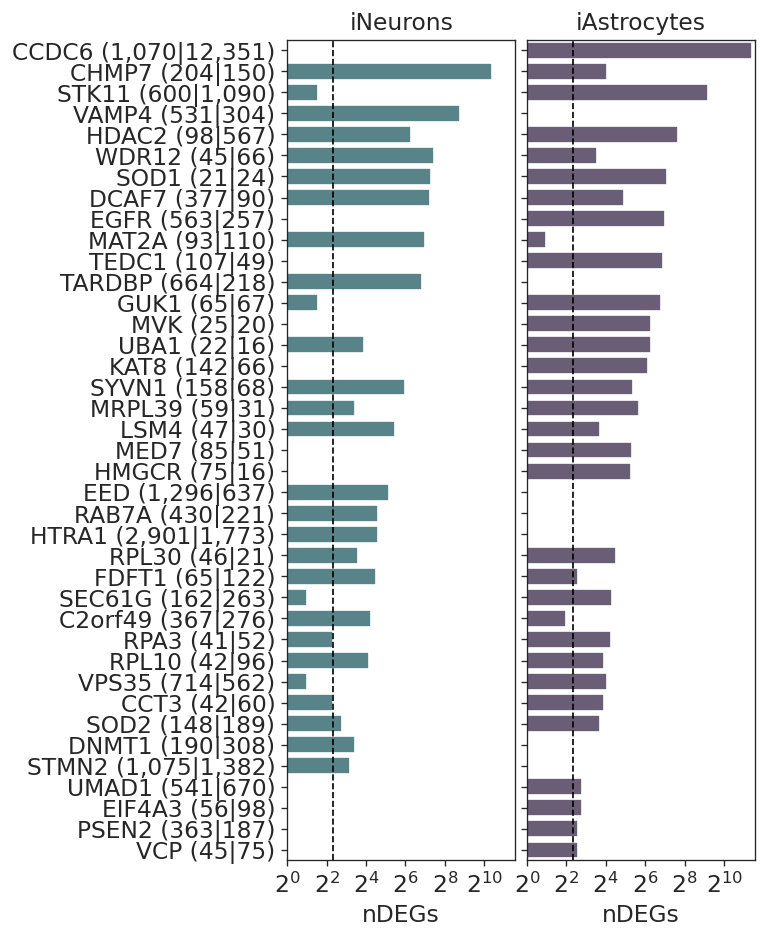

In [37]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(5, 9),
    sharey=True,
    gridspec_kw={"wspace": 0.05}
)

cell_counts = plot_df.pivot(
    index="Gene",
    columns="Cell type",
    values="nCells"
)

plot_df["Gene_label"] = plot_df["Gene"].map(
    lambda gene: (
        f"{gene} "
        f"({int(cell_counts.loc[gene, 'iNeurons']):,}|"
        f"{int(cell_counts.loc[gene, 'iAstrocytes']):,})"
    )
)

plot = (
    plot_df
    .pivot(index="Gene", columns="Cell type", values="nDEGs")
    .loc[gene_order]
)

gene_labels = (
    plot_df
    .drop_duplicates("Gene")
    .set_index("Gene")
    .loc[gene_order, "Gene_label"]
)

sns.barplot(
    x=plot["iNeurons"],
    y=plot.index,
    color="#508991",
    ax=axes[0]
)

sns.barplot(
    x=plot["iAstrocytes"],
    y=plot.index,
    color="#685a7a",
    ax=axes[1]
)

xmin = 1  # log scale cannot include 0
xmax = plot.to_numpy().max() * 1.1  # 10% padding

ticks = [2**i for i in range(0, 11, 2)]  # 1, 4, 16, 64, 256, 1024

for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xlim(xmin, xmax)
    ax.set_xlabel("nDEGs")
    ax.axvline(5, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(ticks)
    ax.set_xticklabels(
        [r"$2^{0}$", r"$2^{2}$", r"$2^{4}$", r"$2^{6}$", r"$2^{8}$", r"$2^{10}$"]
    )

axes[0].set_yticklabels(gene_labels)
axes[0].set_title("iNeurons")
axes[1].set_title("iAstrocytes")
axes[0].set_ylabel("")
axes[1].set_ylabel("")

plt.savefig('figures/barplot_nDEGs.pdf', dpi=300, bbox_inches='tight')

### eDist

In [27]:
cd_iA = sc.read('../cellDisect/iAstrocytes_cellDisect.h5ad')
print (cd_iA.X.shape)
cd_iN = sc.read('../cellDisect/iNeurons_cellDisect_v3_2.h5ad')
print (cd_iN.X.shape)

(195306, 36601)
(204719, 36601)


In [28]:
cd_iA

AnnData object with n_obs × n_vars = 195306 × 36601
    obs: 'target_gene', 'guide_vector', 'sequencing_batch', '_cluster', '_scvi_batch', '_scvi_labels', '_scvi_cluster'
    uns: 'CellDISECT_Z_0_neighbors', 'CellDISECT_Z_not_sequencing_batch_neighbors', 'CellDISECT_Z_sequencing_batch_neighbors', 'CellDISECT_Z_target_gene_neighbors', '_cluster', '_scvi_manager_uuid', '_scvi_uuid', 'log1p', 'neighbors', 'pca', 'sequencing_batch_colors', 'target_gene_colors', 'umap'
    obsm: 'CellDISECT_Z_0', 'CellDISECT_Z_0_umap', 'CellDISECT_Z_not_sequencing_batch', 'CellDISECT_Z_not_sequencing_batch_umap', 'CellDISECT_Z_not_target_gene', 'CellDISECT_Z_sequencing_batch', 'CellDISECT_Z_sequencing_batch_umap', 'CellDISECT_Z_target_gene', 'CellDISECT_Z_target_gene_umap', 'X_pca', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [29]:
cd_iN

AnnData object with n_obs × n_vars = 204719 × 36601
    obs: 'Sample', 'Replicate', 'num_features', 'feature_call', 'num_umis', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'guide_calls', 'target_vector', 'target_gene', 'perturbation', '_cluster', '_scvi_batch', '_scvi_labels', '_scvi_cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'target_gene_id', 'target_gene_name', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'CellDISECT_Z_0_neighbors', 'CellDISECT_Z_Replicate_neighbors', 'CellDISECT_Z_not_Replicate_neighbors', 'CellDISECT_Z_perturbation_neighbors', 'Replicate_colors', '_cluster', '_scvi_manager_uuid', '_scvi_uuid', 'log1p', 'neighbors', 'pca'
    obsm: 'CellDISECT_Z_0', 'CellDISECT_Z_0_umap', 'CellDISECT_Z_Replicate', 'CellDISECT_Z_Replicate_umap', 'CellDISECT_Z_not_Replicate', 'C

In [30]:
keep = genes + ['INT']

In [31]:
print(cd_iA.X.shape)
cd_iA = cd_iA[cd_iA.obs.target_gene.isin(keep)].copy()
print(cd_iA.X.shape)

(195306, 36601)
(28744, 36601)


In [32]:
print(cd_iN.X.shape)
cd_iN = cd_iN[cd_iN.obs.perturbation.isin(keep)].copy()
print(cd_iN.X.shape)

(204719, 36601)
(20061, 36601)


In [2]:
import pertpy as pt
pt.__version__

'1.0.4'

In [33]:
import pertpy as pt
Distance = pt.tools.Distance(metric="edistance", obsm_key="CellDISECT_Z_not_sequencing_batch")
pairwise_df_iA = Distance.onesided_distances(cd_iA, groupby="target_gene", selected_group="INT")

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.5.3 is installed, but it is not compatible with the installed jaxlib version 0.8.2, so it will not be used.
  warnings.warn(
/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
ERROR:2026-08-11 11:59:27,814:jax._src.xla_bridge:475: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 473, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/jax_plugin

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/rich/live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [34]:
import pertpy as pt
Distance = pt.tools.Distance(metric="edistance", obsm_key="CellDISECT_Z_not_Replicate")
pairwise_df_iN = Distance.onesided_distances(cd_iN, groupby="perturbation", selected_group="INT")

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/rich/live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

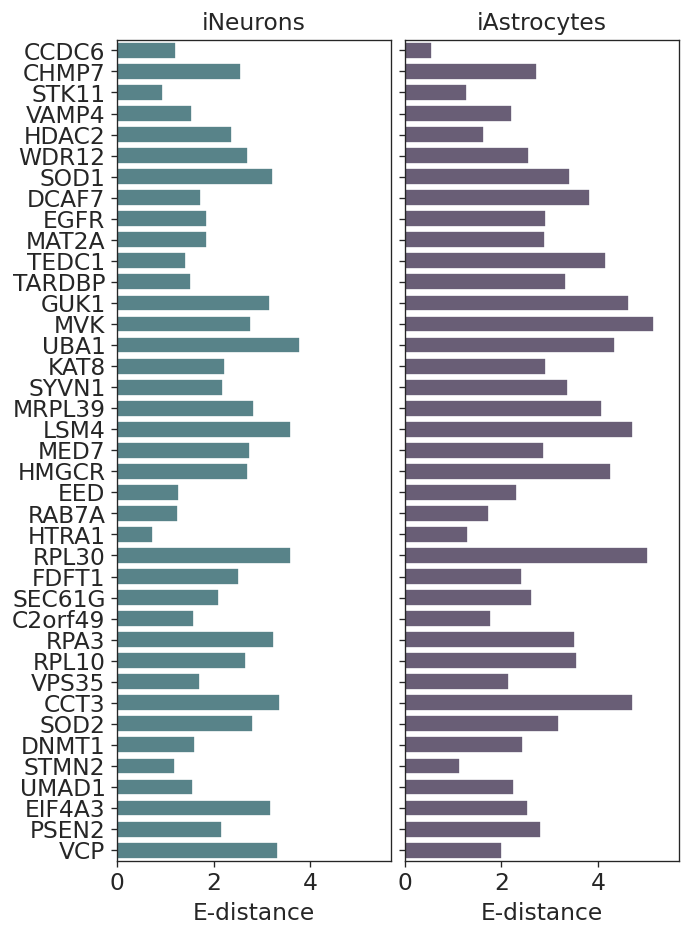

In [35]:
# Convert to Series if needed and remove control
edist_iA = pairwise_df_iA.squeeze().drop(index="INT", errors="ignore")
edist_iN = pairwise_df_iN.squeeze().drop(index="INT", errors="ignore")

# Build dataframe using exactly the same gene order as the nDEG plot
edist_plot = pd.DataFrame({
    "iAstrocytes": edist_iA.reindex(gene_order),
    "iNeurons": edist_iN.reindex(gene_order),
})

# Optional: replace missing perturbations with zero
edist_plot = edist_plot.fillna(0)

fig, axes = plt.subplots(
    1, 2,
    figsize=(6, 9),
    sharey=True,
    gridspec_kw={"wspace": 0.05}
)

sns.barplot(
    x=edist_plot["iNeurons"],
    y=edist_plot.index,
    color="#508991",
    ax=axes[0]
)

sns.barplot(
    x=edist_plot["iAstrocytes"],
    y=edist_plot.index,
    color="#685a7a",
    ax=axes[1]
)

# Identical x limits
xmin = 0
xmax = edist_plot.to_numpy().max() * 1.1

for ax in axes:
    ax.set_xlim(xmin, xmax)
    ax.set_xlabel("E-distance")

axes[1].set_title("iAstrocytes")
axes[00].set_title("iNeurons")
axes[0].set_ylabel("")
axes[1].set_ylabel("")

plt.savefig('figures/barplot_eDistance.pdf', dpi=300)

### cellDisect UMAP

In [36]:
cd_iA = sc.read('../cellDisect/iAstrocytes_cellDisect.h5ad')
print (cd_iA.X.shape)
cd_iN = sc.read('../cellDisect/iNeurons_cellDisect_v3_2.h5ad')
print (cd_iN.X.shape)

(195306, 36601)
(204719, 36601)


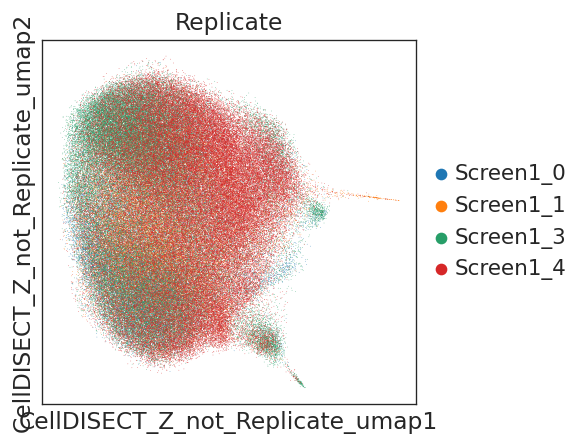

In [37]:
sc.pl.embedding(cd_iN, 'CellDISECT_Z_not_Replicate_umap', color='Replicate')

In [38]:
iN_keep = set(adata_n.obs_names) & set(cd_iN.obs_names)
iN_keep = list(iN_keep)
print (adata_n.X.shape)
adata_n = adata_n[iN_keep].copy()
cd_iN = cd_iN[iN_keep].copy()
adata_n.obsm['CellDISECT_Z_not_Replicate_umap'] = cd_iN.obsm['CellDISECT_Z_not_Replicate_umap']

(204719, 36601)


In [39]:
adata_n.X.max()

np.float32(6620.0)

In [40]:
sc.pp.normalize_total(adata_n, target_sum=1e4)
sc.pp.log1p(adata_n)

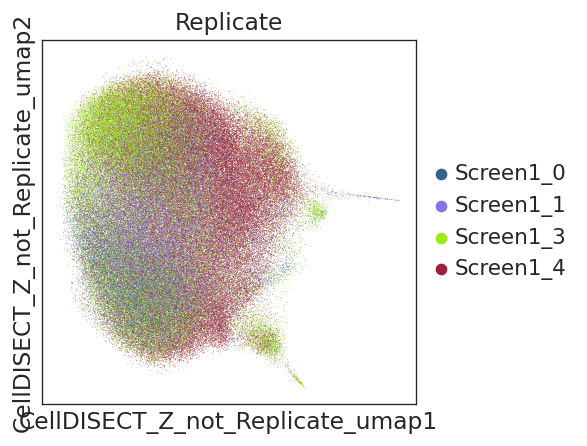

In [41]:
sc.pl.embedding(adata_n, 'CellDISECT_Z_not_Replicate_umap', color='Replicate', palette=["#35618f", "#8872e4", "#9dea19", "#9c2335"],
                save='_iNeurons_screen_cellDisect_batch.pdf'
               )

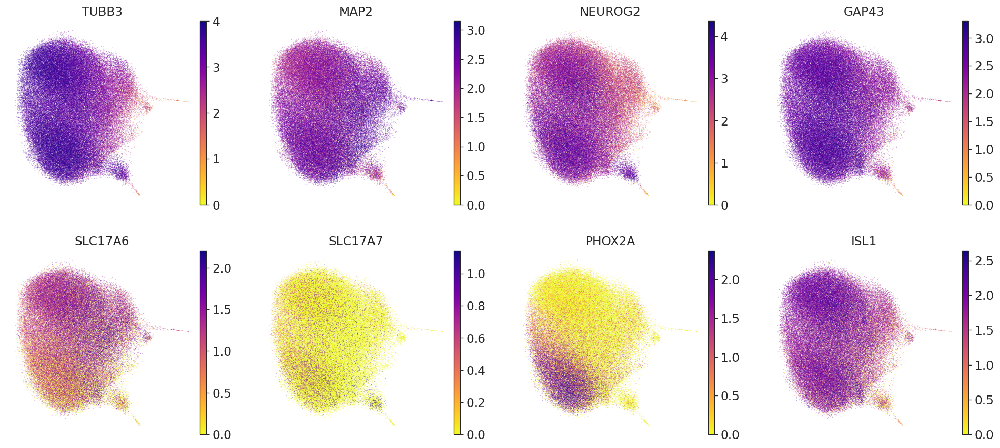

In [42]:
markers = ["TUBB3", "MAP2","NEUROG2",#"RBFOX3",
           "GAP43","SLC17A6", "SLC17A7","PHOX2A","ISL1"]
sc.pl.embedding(adata_n, 'CellDISECT_Z_not_Replicate_umap', color=markers, vmin=0, vmax='p99', cmap='plasma_r',frameon=False,ncols=4,
           save='_iNeurons_screen_cellDisect_markers.pdf'
          )

### cellDisect perturbation space
- highlight top perturbations

In [44]:
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_v3_sig_nDEGs.csv"), index_col=0)

In [45]:
psadata_iA = sc.read('../cellDisect/iAstrocytes_cellDisect_pseudobulk.h5ad')
psadata_iA

AnnData object with n_obs × n_vars = 251 × 96
    obs: 'target_gene', '_scvi_batch', '_scvi_labels', 'psbulk_cells', 'psbulk_counts'
    uns: 'neighbors', 'umap'
    obsm: 'X_umap'
    layers: 'psbulk_props'
    obsp: 'connectivities', 'distances'

In [46]:
psadata_iN = sc.read('../cellDisect/iNeurons_cellDisect_pseudobulk_v3.h5ad')
psadata_iN

AnnData object with n_obs × n_vars = 251 × 96
    obs: 'perturbation', '_scvi_batch', '_scvi_labels', 'psbulk_cells', 'psbulk_counts'
    uns: 'neighbors', 'umap'
    obsm: 'X_umap'
    layers: 'psbulk_props'
    obsp: 'connectivities', 'distances'

In [47]:
for r in [0.2,0.5,0.7,0.8,1.0,1.5]:
    sc.tl.leiden(psadata_iA, resolution=r, key_added=f'leiden_{r}')
    sc.tl.leiden(psadata_iN, resolution=r, key_added=f'leiden_{r}')
    

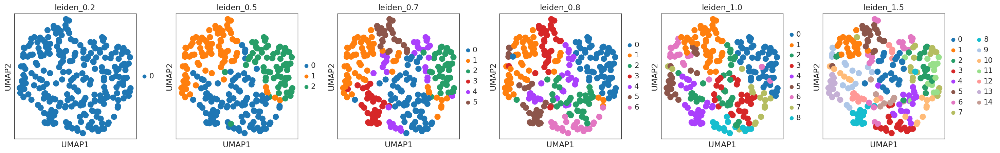

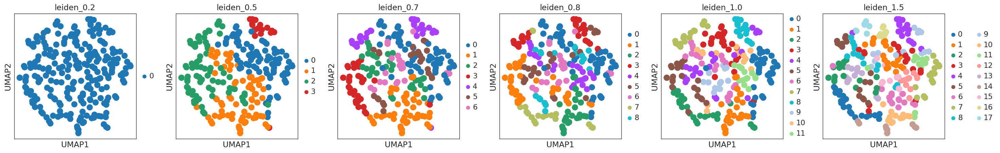

In [48]:
sc.pl.umap(psadata_iA,
           color=list(psadata_iA.obs.columns[psadata_iA.obs.columns.str.startswith('leiden_')]),
           ncols=6)
sc.pl.umap(psadata_iN,
           color=list(psadata_iN.obs.columns[psadata_iN.obs.columns.str.startswith('leiden_')]),
           ncols=6)

In [49]:
psadata_iA.obs

,target_gene,_scvi_batch,_scvi_labels,psbulk_cells,psbulk_counts,leiden_0.2,leiden_0.5,leiden_0.7,leiden_0.8,leiden_1.0,leiden_1.5
CCDC6,CCDC6,0,0,12351.0,4524.407095,0,0,0,2,3,4
RAB29,RAB29,0,0,948.0,3335.964221,0,2,2,0,0,11
INT,INT,0,0,6111.0,-16200.946105,0,0,0,2,3,14
SORT1,SORT1,0,0,469.0,-382.505742,0,1,1,1,5,13
SPI1,SPI1,0,0,794.0,381.001989,0,1,4,3,5,9
...,...,...,...,...,...,...,...,...,...,...,...
RPA3,RPA3,0,0,52.0,76.246281,0,1,5,3,1,5
GUK1,GUK1,0,0,67.0,20.963336,0,2,2,0,0,7
WDR12,WDR12,0,0,66.0,55.183547,0,1,1,1,1,1
USP8,USP8,0,0,165.0,-20.448235,0,0,0,2,2,14


In [50]:
leiden_genes = psadata_iA.obs.groupby("leiden_0.8")["target_gene"].apply(list).to_dict()

In [51]:
import gseapy as gp

def enrichment_heatmap(gene_dict, gene_sets=None, organism='human', top_n=5, fdr_cutoff=0.05):
    """
    Perform enrichment analysis and create a heatmap of top GO terms.

    Parameters:
        gene_dict (dict): Dictionary containing list of genes to perform GEA on
        gene_sets (list): List of gene sets for enrichment analysis (default GO + MSigDB).
        organism (str): Organism for enrichment ('human', 'mouse', etc.).
        top_n (int): Number of GO terms to keep.
        fdr_cutoff (float): FDR threshold for significance.

    Returns:
        GO_res (DataFrame): Filtered -log10(p-value) enrichment matrix.
        enr_dict (dict): Dictionary of raw enrichment results per perturbation.
    """
    
    if gene_sets is None:
        gene_sets = ['GO_Biological_Process_2025','MSigDB_Hallmark_2020','GO_Cellular_Component_2025','GO_Molecular_Function_2025',
                     'Reactome_2022','CellMarker_2024' #'Reactome_Pathways_2024',
                    ]

    # Run enrichment for each GP
    enr_dict = {}
    for key in gene_dict:
        enr = gp.enrichr(
            gene_list=gene_dict[key],#['variable'].to_list(),
            gene_sets=gene_sets,
            organism=organism,
            outdir=None,
        )
        if isinstance(enr.results, pd.DataFrame) and not enr.results.empty:
            enr_dict[key] = enr.results.sort_values("Adjusted P-value")
        else:
            print(f"No enrichment results for {key}")
            enr_dict[key] = pd.DataFrame(columns=["Term", "Adjusted P-value"])

    # Transform results to -log10(p-value)
    pvalues = {}
    for key, df in enr_dict.items():
        df_top = df[["Term","Adjusted P-value"]].head(top_n).copy()
        df_top = df_top.rename(columns={'Adjusted P-value': key}).set_index("Term")
        df_top[key] = -np.log10(df_top[key])
        pvalues[key] = df_top

    minuslogp = pd.concat(pvalues.values(), axis=0, join="outer")
    minuslogp = minuslogp.groupby(level=0).sum()

    # keep significant GO terms
    minuslogp_bool = (minuslogp <= -np.log10(fdr_cutoff)).all(axis=1)
    GO_res = minuslogp[~minuslogp_bool]

    print(f"GO terms shape (significant): {GO_res.shape}")
    
    return GO_res, enr_dict

In [52]:
import requests
def get_enrichr_library(library_name):
    url = "https://maayanlab.cloud/Enrichr/geneSetLibrary"
    r = requests.get(
        url,
        params={"mode": "text", "libraryName": library_name},
        timeout=60,
    )
    r.raise_for_status()
    genesets = {}
    for line in r.text.strip().splitlines():
        parts = line.split("\t")
        genesets[parts[0]] = [g.split(",")[0] for g in parts[2:]]
    return genesets

#tabula = get_enrichr_library("Tabula_Sapiens")
GO = get_enrichr_library("GO_Biological_Process_2025")
reactome = get_enrichr_library("Reactome_Pathways_2024")
hallmarks = get_enrichr_library("MSigDB_Hallmark_2020")
kegg = get_enrichr_library("KEGG_2021_Human")
go_mf = get_enrichr_library("GO_Molecular_Function_2025")
go_cc = get_enrichr_library("GO_Cellular_Component_2025")
wiki = get_enrichr_library("WikiPathways_2024_Human")
archs4_tissues = get_enrichr_library("ARCHS4_Tissues")
gtex_tissues = get_enrichr_library("GTEx_Tissues_V8_2023")
human_gene_atlas = get_enrichr_library("Human_Gene_Atlas")
cellmarker = get_enrichr_library("CellMarker_2024")
panglao = get_enrichr_library("PanglaoDB_Augmented_2021")
azimuth = get_enrichr_library("Azimuth_2023")
descartes = get_enrichr_library("Descartes_Cell_Types_and_Tissue_2021")
compartments = get_enrichr_library("COMPARTMENTS_Curated_2025")
tissues_curated = get_enrichr_library("TISSUES_Curated_2025")

/tmp/ipykernel_83861/1554412867.py:27: UserWarning: The palette list has more values (8) than needed (7), which may not be intended.
  sns.scatterplot(


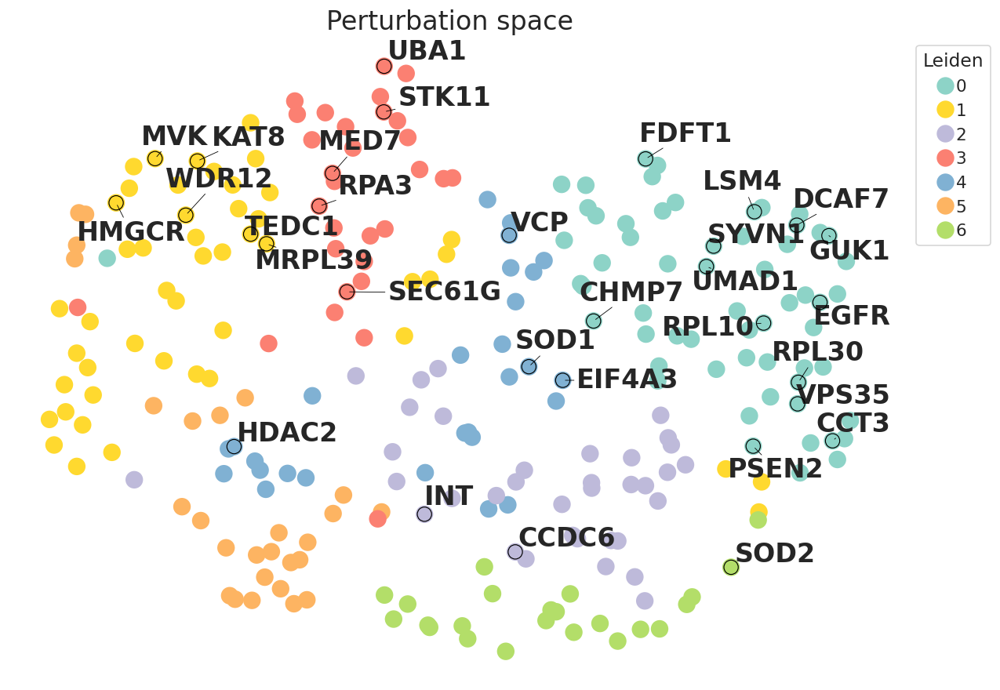

In [53]:
pal_col = ['#8dd3c7', '#ffd92f', '#bebada', '#fb8072', '#80b1d3', '#fdb462', '#b3de69', '#fccde5']

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

new_adata = psadata_iA

# UMAP DataFrame
umap_df = pd.DataFrame(new_adata.obsm['X_umap'], columns=['UMAP1', 'UMAP2'])
umap_df['gene'] = new_adata.obs_names.astype(str).values
umap_df['leiden'] = new_adata.obs['leiden_0.8'].astype(str).values

# Order categories numerically: 0, 1, 2, ...
cats = sorted(umap_df['leiden'].unique(), key=int)
umap_df['leiden'] = pd.Categorical(
    umap_df['leiden'],
    categories=cats,
    ordered=True
)

# Genes to highlight
highlight_genes = list(iA_nDEGs_df.query("nDEGs >= 5").index)

plt.figure(figsize=(12, 9))
sns.scatterplot(
    data=umap_df, x='UMAP1', y='UMAP2',
    hue='leiden',
    palette=pal_col,
    #color='#b0b0b0',
    alpha=1, s=180, linewidth=0
)

texts = []
for gene in highlight_genes + ['INT']:
    mask = umap_df['gene'].str.upper() == gene.upper()
    if mask.any():
        plt.scatter(
            umap_df.loc[mask, 'UMAP1'],
            umap_df.loc[mask, 'UMAP2'],
            s=120, linewidths=0.7, edgecolors='k', facecolors='none', zorder=5
        )
        x_med, y_med = umap_df.loc[mask, ['UMAP1','UMAP2']].median()
        texts.append(plt.text(x_med, y_med, gene, fontsize=20, weight='bold'))

adjust_text(texts, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))
plt.legend(title='Leiden', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.axis('off'); plt.grid(False)
plt.title("Perturbation space", fontsize=20)
plt.savefig('figures/iAstrocytes_perurbationMap_CellDISECT_Z_not_sequencing_batch2_2.pdf', dpi=300, bbox_inches='tight')


/tmp/ipykernel_83861/198802031.py:25: UserWarning: The palette list has more values (8) than needed (7), which may not be intended.
  sns.scatterplot(


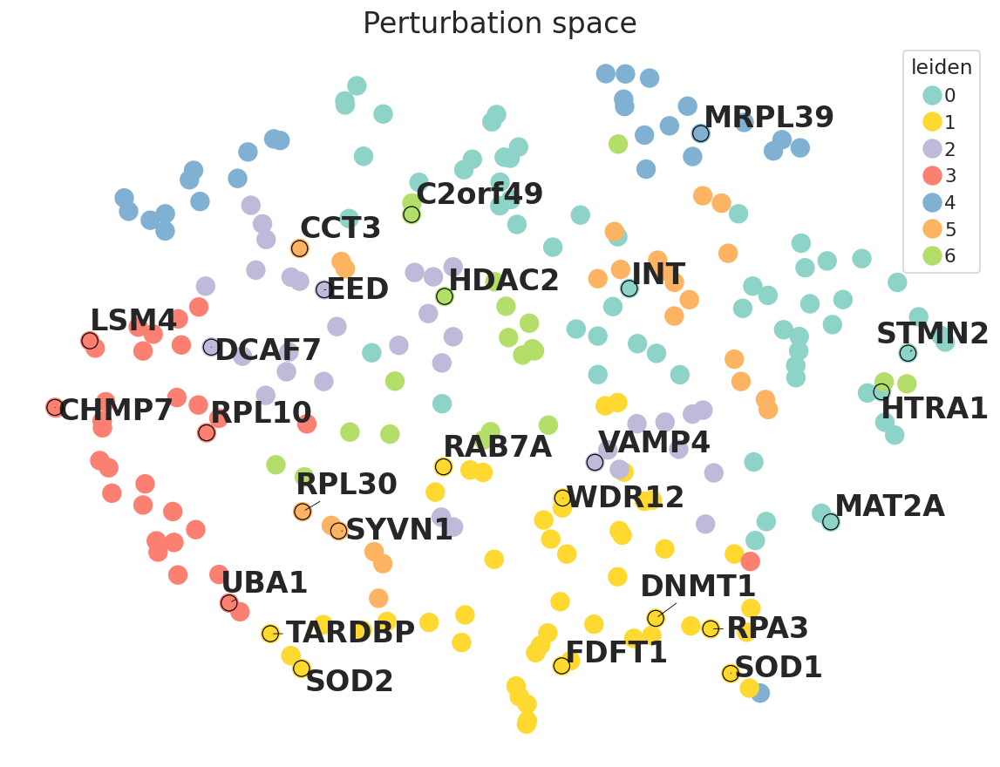

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

new_adata = psadata_iN

# UMAP DataFrame
umap_df = pd.DataFrame(new_adata.obsm['X_umap'], columns=['UMAP1', 'UMAP2'])
umap_df['gene'] = new_adata.obs_names.astype(str).values
umap_df['leiden'] = new_adata.obs['leiden_0.7'].astype(str).values

# Order categories numerically: 0, 1, 2, ...
cats = sorted(umap_df['leiden'].unique(), key=int)
umap_df['leiden'] = pd.Categorical(
    umap_df['leiden'],
    categories=cats,
    ordered=True
)

# Genes to highlight
highlight_genes = list(iN_nDEGs_df.query("nDEGs >= 5").index)

plt.figure(figsize=(12, 9))
sns.scatterplot(
    data=umap_df, x='UMAP1', y='UMAP2',
    hue='leiden',
    palette=pal_col,
    #color='#b0b0b0',
    alpha=1, s=180, linewidth=0
)

texts = []
for gene in highlight_genes + ['INT']:
    mask = umap_df['gene'].str.upper() == gene.upper()
    if mask.any():
        plt.scatter(
            umap_df.loc[mask, 'UMAP1'],
            umap_df.loc[mask, 'UMAP2'],
            s=120, linewidths=0.7, edgecolors='k', facecolors='none', zorder=5
        )
        x_med, y_med = umap_df.loc[mask, ['UMAP1','UMAP2']].median()
        texts.append(plt.text(x_med, y_med, gene, fontsize=20, weight='bold'))

adjust_text(texts, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))
plt.axis('off'); plt.grid(False)
plt.title("Perturbation space", fontsize=20)
plt.savefig('figures/iNeurons_perurbationMap_CellDISECT_Z_not_replicate_v3_2.pdf', dpi=300, bbox_inches='tight')


In [55]:
iA_nDEGs_df.index

Index(['AARD', 'ABCA1', 'ABCA7', 'ACE', 'ACTR2', 'ADAM10', 'ADAM17', 'AGRN',
       'ALKBH5', 'ANK2',
       ...
       'VWDE', 'WDR12', 'WDR45B', 'WDR81', 'WWOX', 'YWHAQ', 'ZBTB46', 'ZCWPW1',
       'ZNF518A', 'ZYX'],
      dtype='object', length=248)

In [56]:
leiden_genes = psadata_iA.obs.groupby("leiden_0.8")["target_gene"].apply(list).to_dict()

In [57]:
GO_res_a, enr_dict = enrichment_heatmap(
    gene_dict=leiden_genes,
    gene_sets=[GO, reactome, hallmarks, kegg, go_mf, go_cc, wiki,],
    top_n=8,
    fdr_cutoff=0.05,
)

GO terms shape (significant): (46, 7)


In [58]:
df = pd.DataFrame({k: pd.Series(v) for k, v in leiden_genes.items()})
df.to_csv("perturbationSpace_iAstrocytes_clusters.csv2", index=False)

In [59]:
GO_res_a.to_csv("perturbationSpace_iAstrocytes_clusters_GO2.csv")

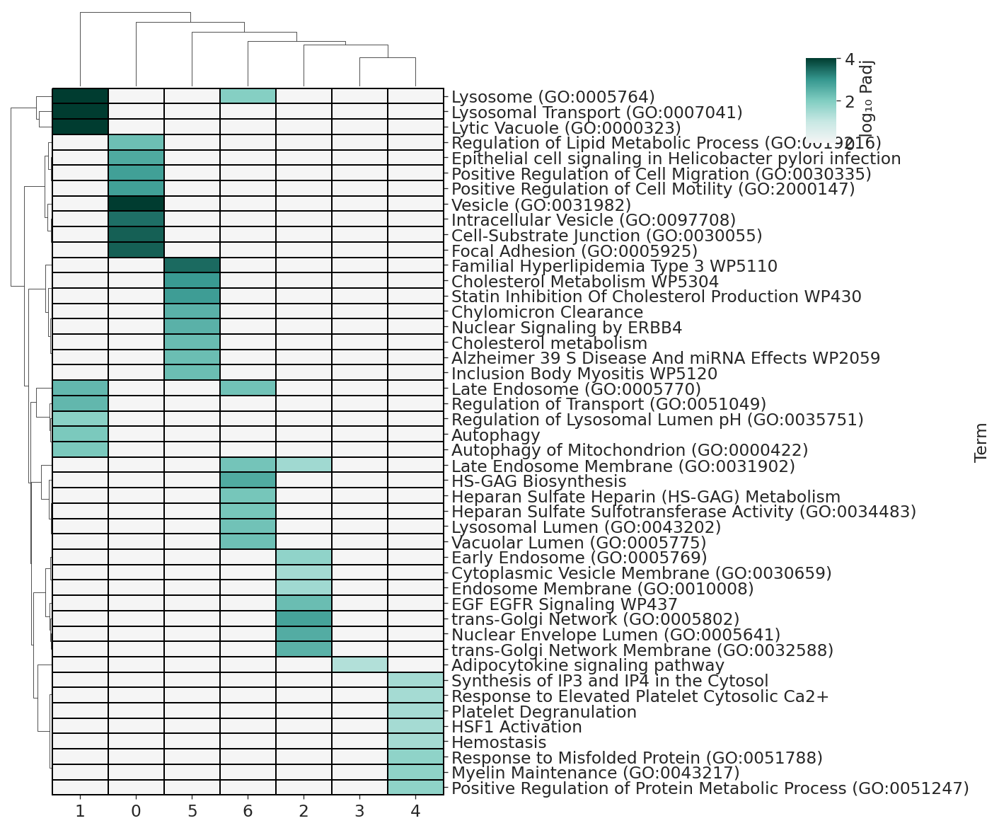

In [60]:
g = sns.clustermap(
    GO_res_a,
    vmax=4, cmap=cmap, linewidths=1, linecolor='black', clip_on=False,
    dendrogram_ratio = 0.1,
    figsize=(12,10),
    cbar_pos=(0.8, 0.82, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    yticklabels=1,   # force every row label
    #xticklabels=1    # force every column label (optional)
)

# Shrink fonts after creation
#g.ax_heatmap.tick_params(axis='y', labelsize=8)
#g.ax_heatmap.tick_params(axis='x', labelsize=10, )
plt.savefig("figures/heatmap_pseudobulk_leiden_iAstrocytes2.pdf", bbox_inches='tight')

In [61]:
leiden_genes = psadata_iN.obs.groupby("leiden_0.7")["perturbation"].apply(list).to_dict()

GO_res_n, enr_dict = enrichment_heatmap(
    gene_dict=leiden_genes,
    gene_sets=[GO, reactome, hallmarks, kegg, go_mf, go_cc, wiki,],
    top_n=8,
    fdr_cutoff=0.05,
)

GO terms shape (significant): (54, 7)


In [62]:
leiden_genes.keys()

dict_keys(['0', '1', '2', '3', '4', '5', '6'])

In [63]:
df = pd.DataFrame({k: pd.Series(v) for k, v in leiden_genes.items()})
df.to_csv("perturbationSpace_iNeurons_clusters.csv", index=False)
GO_res_n.to_csv("perturbationSpace_iNeurons_clusters_GO2.csv")

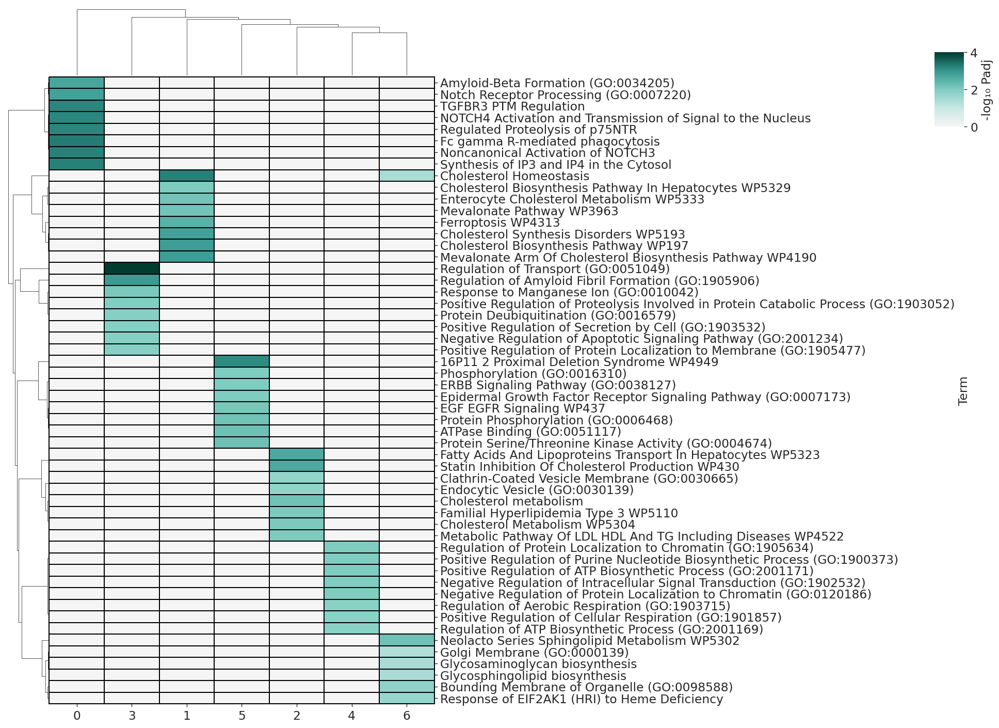

In [64]:
g = sns.clustermap(
    GO_res_n,
    vmax=4, cmap=cmap, linewidths=1, linecolor='black', clip_on=False,
    dendrogram_ratio = 0.1,
    figsize=(16,12),
    cbar_pos=(0.95, 0.82, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    yticklabels=1,   # force every row label
    #xticklabels=1    # force every column label (optional)
)

# Shrink fonts after creation
#g.ax_heatmap.tick_params(axis='y', labelsize=8)
#g.ax_heatmap.tick_params(axis='x', labelsize=10, )
plt.savefig("figures/heatmap_pseudobulk_leiden_iNeurons2.pdf", bbox_inches="tight")

In [65]:
cluster_names_iA = {
    "0": "Vesicle trafficking & adhesion",
    "1": "Lysosome & autophagy",
    "2": "Endosomal-Golgi trafficking",
    "3": "Signal transduction & membrane trafficking",
    "4": "Proteostasis & stress response",
    "5": "Lipid & cholesterol metabolism",
    "6": "Lysosomal homeostasis & HS-GAG biosynthesis",
}

cluster_names_iN = {
    "0": "Endolysosomal signalling & processing",
    "1": "Cholesterol biosynthesis & endolysosomal trafficking",
    "2": "Cholesterol metabolism & endocytic trafficking",
    "3": "Protein trafficking & proteostasis",
    "4": "Mitochondrial homeostasis & stress response",
    "5": "Cell signalling & phosphorylation",
    "6": "Golgi & lipid homeostasis",
}

/tmp/ipykernel_83861/2049862321.py:30: UserWarning: The palette list has more values (8) than needed (7), which may not be intended.
  sns.scatterplot(


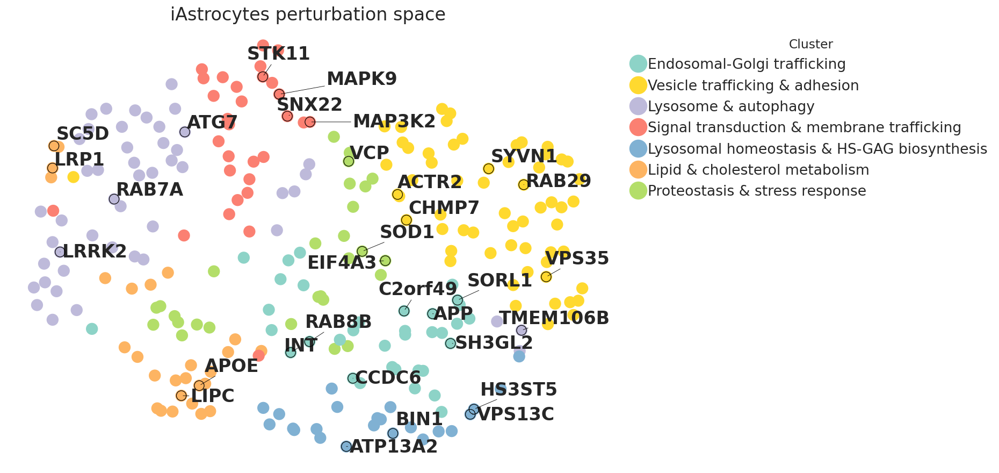

In [66]:
pal_col = ['#8dd3c7', '#ffd92f', '#bebada', '#fb8072', '#80b1d3', '#fdb462', '#b3de69', '#fccde5']

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

new_adata = psadata_iA

# UMAP DataFrame
umap_df = pd.DataFrame(new_adata.obsm['X_umap'], columns=['UMAP1', 'UMAP2'])
umap_df['gene'] = new_adata.obs_names.astype(str).values
umap_df['leiden'] = new_adata.obs['leiden_0.8'].astype(str).values
umap_df["cluster"] = umap_df["leiden"].map(cluster_names_iA)

# Genes to highlight
#highlight_genes = list(iA_nDEGs_df.query("nDEGs >= 5").index)
highlight_genes = ['CHMP7','VPS35','RAB29','ACTR2',#0 vesicle traficking and adhesion
                   'RAB7A','TMEM106B','ATG7','LRRK2', #lysosome and autophagy
                   'RAB8B','SH3GL2','APP','SORL1', #1 endosomal-golgi
                   'MAPK9','MAP3K2','STK11','SNX22', #3 siganlling
                   'VCP','SOD1','EIF4A3','VCP', #Proteostassis
                   'APOE','LRP1','SC5D','LIPC', #5 lippds
                   'ATP13A2','BIN1','VPS13C','HS3ST5',
                   'VPS35','RAB7A','CCDC6','C2orf49','SYVN1','MAPK9','APOE','VCP','APP','LRP1'
                  ]
highlight_genes = sorted(set(highlight_genes))

plt.figure(figsize=(12, 9))
sns.scatterplot(
    data=umap_df, x='UMAP1', y='UMAP2',
    hue='cluster',
    palette=pal_col,
    #color='#b0b0b0',
    alpha=1, s=180, linewidth=0
)

texts = []
for gene in highlight_genes + ['INT']:
    mask = umap_df['gene'].str.upper() == gene.upper()
    if mask.any():
        plt.scatter(
            umap_df.loc[mask, 'UMAP1'],
            umap_df.loc[mask, 'UMAP2'],
            s=120, linewidths=0.7, edgecolors='k', facecolors='none', zorder=5
        )
        x_med, y_med = umap_df.loc[mask, ['UMAP1','UMAP2']].median()
        texts.append(plt.text(x_med, y_med, gene, fontsize=20, weight='bold'))

adjust_text(texts, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False, 
           fontsize=16, markerscale=1.5)
plt.axis('off'); plt.grid(False)
plt.title("iAstrocytes perturbation space", fontsize=20)
plt.savefig('figures/iAstrocytes_perurbationMap_CellDISECT_Z_not_sequencing_batch3.pdf', dpi=300, bbox_inches='tight')


/tmp/ipykernel_83861/2180900292.py:28: UserWarning: The palette list has more values (8) than needed (7), which may not be intended.
  sns.scatterplot(


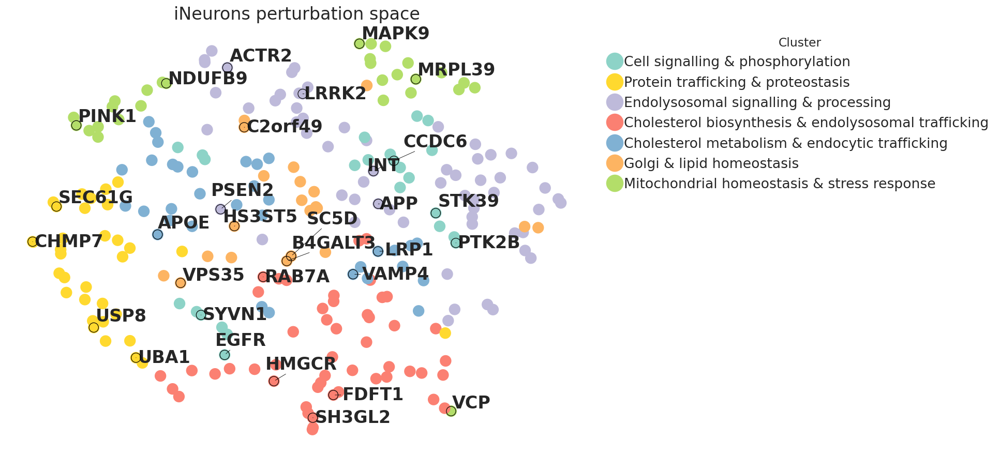

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

new_adata = psadata_iN

# UMAP DataFrame
umap_df = pd.DataFrame(new_adata.obsm['X_umap'], columns=['UMAP1', 'UMAP2'])
umap_df['gene'] = new_adata.obs_names.astype(str).values
umap_df['leiden'] = new_adata.obs['leiden_0.7'].astype(str).values
umap_df["cluster"] = umap_df["leiden"].map(cluster_names_iN)

# Genes to highlight
#highlight_genes = list(iA_nDEGs_df.query("nDEGs >= 5").index)
highlight_genes = ['PSEN2','APP','LRRK2','ACTR2',#0 Endolysosomal signalling & processing
                   'HMGCR','FDFT1','RAB7A','SH3GL2', #C1holesterol biosynthesis & endolysosomal trafficking
                   'APOE','LRP1','VAMP4', #2 cholesterol metabolism & endoyctic trafficking
                   'CHMP7','SEC61G','UBA1','USP8', #3 Protein trafficking & proteostasis
                   'VCP','MAPK9','PINK1','VCP','NDUFB9','MRPL39', #Mitochondrial homeostasis & stress response
                   'EGFR','STK39','PTK2B', #5 Cell signalling & phosphorylation
                   'VPS35','B4GALT3','SC5D','HS3ST5', #golgi
                   'VPS35','RAB7A','CCDC6','C2orf49','SYVN1','MAPK9','APOE','VCP','APP','LRP1'
                  ]
highlight_genes = sorted(set(highlight_genes))

plt.figure(figsize=(12, 9))
sns.scatterplot(
    data=umap_df, x='UMAP1', y='UMAP2',
    hue='cluster',
    palette=pal_col,
    #color='#b0b0b0',
    alpha=1, s=180, linewidth=0
)

texts = []
for gene in highlight_genes + ['INT']:
    mask = umap_df['gene'].str.upper() == gene.upper()
    if mask.any():
        plt.scatter(
            umap_df.loc[mask, 'UMAP1'],
            umap_df.loc[mask, 'UMAP2'],
            s=120, linewidths=0.7, edgecolors='k', facecolors='none', zorder=5
        )
        x_med, y_med = umap_df.loc[mask, ['UMAP1','UMAP2']].median()
        texts.append(plt.text(x_med, y_med, gene, fontsize=20, weight='bold'))

adjust_text(texts, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False, 
           fontsize=16, markerscale=1.5)
plt.axis('off'); plt.grid(False)
plt.title("iNeurons perturbation space", fontsize=20)
plt.savefig('figures/iNeurons_perurbationMap_CellDISECT_Z_not_sequencing_batch3.pdf', dpi=300, bbox_inches='tight')


In [68]:
GO_res_a = GO_res_a.rename(columns=cluster_names_iA)
GO_res_n = GO_res_n.rename(columns=cluster_names_iN)

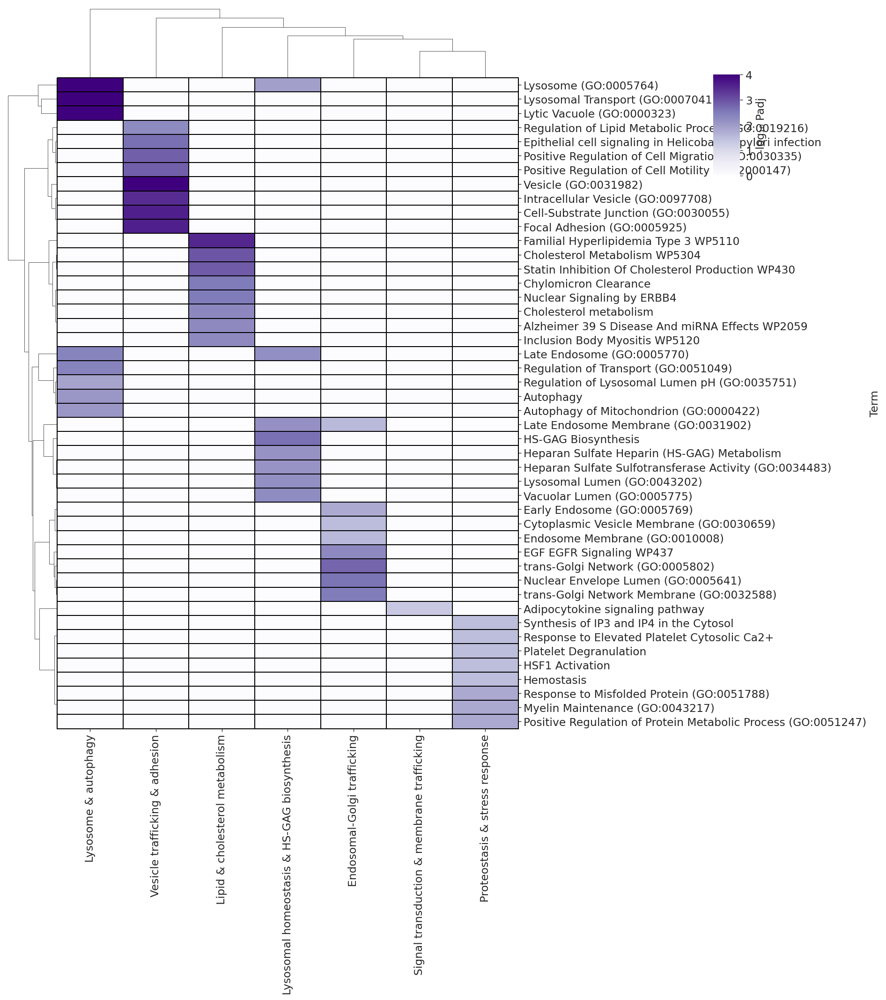

In [70]:
g = sns.clustermap(
    GO_res_a,
    vmax=4, cmap='Purples', linewidths=1, linecolor='black', clip_on=False,
    dendrogram_ratio = 0.1,
    figsize=(16,18),
    cbar_pos=(0.8, 0.82, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    yticklabels=1,   # force every row label
    #xticklabels=1    # force every column label (optional)
)

# Shrink fonts after creation
#g.ax_heatmap.tick_params(axis='y', labelsize=8)
#g.ax_heatmap.tick_params(axis='x', labelsize=10, )
plt.savefig("figures/heatmap_pseudobulk_leiden_iAstrocytes2.pdf", bbox_inches='tight')

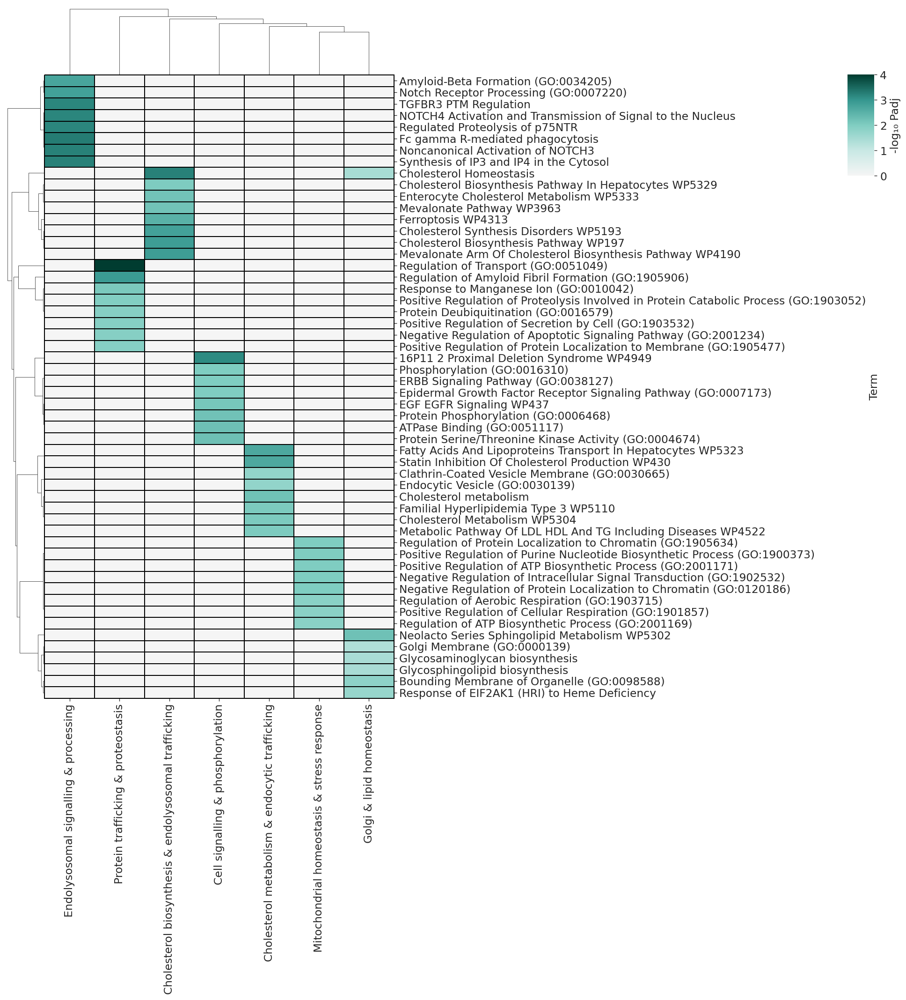

In [71]:
g = sns.clustermap(
    GO_res_n,
    vmax=4, cmap=cmap, linewidths=1, linecolor='black', clip_on=False,
    dendrogram_ratio = 0.1,
    figsize=(16,18),
    cbar_pos=(0.95, 0.82, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    yticklabels=1,   # force every row label
    #xticklabels=1    # force every column label (optional)
)

# Shrink fonts after creation
#g.ax_heatmap.tick_params(axis='y', labelsize=8)
#g.ax_heatmap.tick_params(axis='x', labelsize=10, )
plt.savefig("figures/heatmap_pseudobulk_leiden_iNeurons2.pdf", bbox_inches="tight")